# Creative Gaming: Uplift Modeling

* Team-lead GitHub userid: rsm-ygadhiya
* Group name:
* Team member names:
    - Namratha K
    - Aanya Sikka
    - Yug Gadhiya

## Setup

Please complete this python notebook **with your group** by answering the questions in case05 on the course website. Create a Notebook with all your results and comments and push the Notebook to GitHub when your team is done. All results MUST be reproducible (i.e., the TA and I must be able to recreate your output from the Jupyter Notebook without changes or errors). This means that you should NOT use any python-packages that are not part of the RSM-MSBA docker container.

This is a group assignment for MGTA 455 and you will be using Git and GitHub. If two people edit the same file at the same time you could get what is called a "merge conflict". This is not something serious but you should realize that Git will not decide for you who's changes to accept. The team-lead will have to determine the edits to use. To avoid merge conflicts, **always** "pull" changes to the repo before you start working on any files. Then, when you are done, save and commit your changes, and then push them to GitHub. Make "pull first" a habit!

### Tools to use

* Use polars, not pandas. Use plotnine, not matplotlib or seaborn. Use pyrsm AND sklearn for machine learning models. Do NOT use sklearn for linear or logistic regression. Use pyrsm for linear and logistic regression instead, which is built on statsmodels. Use numpy only if you cannot do something with polars.
* If you want AI-help for polars, use the documentation AI here: https://docs.pola.rs/api/python/stable/reference/index.html
* Use the pyrsm documentation for help with machine learning models (https://github.com/vnijs/pyrsm) and review the example notebooks in <https://github.com/vnijs/pyrsm/tree/main/examples>. For example, the `models` folder contains examples of how to use logistic regression, random forests, xgboost, and MLPs in pyrsm. You can also refer to the sklearn documentation for help with tree-based models and neural networks, but make sure to use pyrsm for estimation and cross-validation **first** and then use sklearn to replicate the results

In [37]:
import polars as pl
import pyrsm as rsm

In [38]:
# update pyrsm to version 2.3.0
!uv --project /opt/base-uv add pyrsm==2.3.0

Resolved 220 packages in 6ms
Audited 203 packages in 23ms


In [39]:
## loading the organic data - this dataset must NOT be changed
cg_organic_control = pl.read_parquet("data/cg_organic_control.parquet")
cg_organic_control.head()

converted,GameLevel,NumGameDays,NumGameDays4Plus,NumInGameMessagesSent,NumSpaceHeroBadges,NumFriendRequestIgnored,NumFriends,AcquiredSpaceship,AcquiredIonWeapon,TimesLostSpaceship,TimesKilled,TimesCaptain,TimesNavigator,PurchasedCoinPackSmall,PurchasedCoinPackLarge,NumAdsClicked,DaysUser,UserConsole,UserHasOldOS
cat,i32,i32,i32,i32,i32,i32,i32,cat,cat,i32,i32,i32,i32,cat,cat,i32,i32,cat,cat
"""no""",7,18,0,124,0,81,0,"""yes""","""no""",8,0,0,4,"""no""","""yes""",3,2101,"""no""","""no"""
"""no""",10,3,2,60,0,18,479,"""no""","""no""",10,7,0,0,"""yes""","""no""",7,1644,"""yes""","""no"""
"""no""",2,1,0,0,0,0,0,"""no""","""no""",0,0,0,2,"""no""","""no""",8,3197,"""yes""","""yes"""
"""no""",2,11,1,125,0,73,217,"""no""","""no""",0,0,0,0,"""yes""","""no""",6,913,"""no""","""no"""
"""no""",8,15,0,0,0,6,51,"""yes""","""no""",0,0,2,1,"""yes""","""no""",21,2009,"""yes""","""no"""


In [40]:
rsm.md("data/cg_organic_control_description.md")

## Creative gaming

Game telemetry dataset used for the Creative Gaming: Propensity-to-Buy Modeling case

#### Feature descriptions

* converted: Purchased the Zalon campain ("yes" or "no")
* GameLevel: Highest level of game achieved by the user
* NumGameDays: Number of days user played the game in last month (with or without network connection)
* NumGameDays4Plus: Number of days user played the game in last month with 4 or more total users (this implies using a network connection)
* NumInGameMessagesSent: Number of in-game messages sent to friends
* NumFriends: Number of friends to which the user is connected (necessary to crew together in multiplayer mode) 
* NumFriendRequestIgnored: Number of friend requests this user has not replied to since game inception
* NumSpaceHeroBadges: Number of "Space Hero" badges, the highest distinction for gameplay in Space Pirates
* AcquiredSpaceship: Flag if the user owns a spaceship, i.e., does not have to crew on another user's or NPC's space ship ("no" or "yes")
* AcquiredIonWeapon: Flag if the user owns the powerful "ion weapon" ("no" or "yes")
* TimesLostSpaceship: The number of times the user destroyed his/her spaceship during gameplay. Spaceships need to be re-acquired if destroyed.
* TimesKilled: Number of times the user was killed during gameplay
* TimesCaptain: Number of times in last month that the user played in the role of a captain
* TimesNavigator: Number of times in last month that the user played in the role of a navigator
* PurchasedCoinPackSmall: Flag if the user purchased a small pack of Zathium in last month ("no" or "yes")
* PurchasedCoinPackLarge: Flag if the user purchased a large pack of Zathium in last month ("no" or "yes")
* NumAdsClicked: Number of in-app ads the user has clicked on
* DaysUser: Number of days since user established a user ID with Creative Gaming (for Space Pirates or previous games)
* UserConsole: Flag if the user plays Creative Gaming games on a console ("no" or "yes")
* UserHasOldOS: Flag if the user has iOS version 10 or earlier ("no" or "yes")


In [41]:
## loading the treatment data - this dataset must NOT be changed
cg_ad_treatment = pl.read_parquet("data/cg_ad_treatment.parquet")
cg_ad_treatment.head()

converted,GameLevel,NumGameDays,NumGameDays4Plus,NumInGameMessagesSent,NumSpaceHeroBadges,NumFriendRequestIgnored,NumFriends,AcquiredSpaceship,AcquiredIonWeapon,TimesLostSpaceship,TimesKilled,TimesCaptain,TimesNavigator,PurchasedCoinPackSmall,PurchasedCoinPackLarge,NumAdsClicked,DaysUser,UserConsole,UserHasOldOS,rnd_30k
cat,i32,i32,i32,i32,i32,i32,i32,cat,cat,i32,i32,i32,i32,cat,cat,i32,i32,cat,cat,i32
"""no""",6,16,0,0,0,0,0,"""yes""","""no""",0,0,0,0,"""no""","""no""",11,1827,"""no""","""no""",0
"""no""",2,8,0,0,0,5,4,"""no""","""no""",0,0,8,0,"""yes""","""no""",3,1889,"""no""","""yes""",1
"""no""",6,1,0,0,0,0,0,"""no""","""no""",0,0,0,0,"""no""","""yes""",2,1948,"""yes""","""no""",0
"""yes""",7,16,0,102,1,0,194,"""no""","""no""",0,0,0,0,"""yes""","""yes""",21,3409,"""yes""","""yes""",0
"""no""",10,1,1,233,0,23,0,"""no""","""no""",3,0,5,0,"""no""","""yes""",4,2922,"""yes""","""no""",0


In [42]:
rsm.md("data/cg_ad_treatment_description.md")

## Creative gaming

Game telemetry dataset used for the Creative Gaming: Propensity-to-Buy Modeling case

#### Feature descriptions

* converted: Purchased the Zalon campain ("yes" or "no")
* GameLevel: Highest level of game achieved by the user
* NumGameDays: Number of days user played the game in last month (with or without network connection)
* NumGameDays4Plus: Number of days user played the game in last month with 4 or more total users (this implies using a network connection)
* NumInGameMessagesSent: Number of in-game messages sent to friends
* NumFriends: Number of friends to which the user is connected (necessary to crew together in multiplayer mode) 
* NumFriendRequestIgnored: Number of friend requests this user has not replied to since game inception
* NumSpaceHeroBadges: Number of "Space Hero" badges, the highest distinction for gameplay in Space Pirates
* AcquiredSpaceship: Flag if the user owns a spaceship, i.e., does not have to crew on another user's or NPC's space ship ("no" or "yes")
* AcquiredIonWeapon: Flag if the user owns the powerful "ion weapon" ("no" or "yes")
* TimesLostSpaceship: The number of times the user destroyed his/her spaceship during gameplay. Spaceships need to be re-acquired if destroyed.
* TimesKilled: Number of times the user was killed during gameplay
* TimesCaptain: Number of times in last month that the user played in the role of a captain
* TimesNavigator: Number of times in last month that the user played in the role of a navigator
* PurchasedCoinPackSmall: Flag if the user purchased a small pack of Zathium in last month ("no" or "yes")
* PurchasedCoinPackLarge: Flag if the user purchased a large pack of Zathium in last month ("no" or "yes")
* NumAdsClicked: Number of in-app ads the user has clicked on
* DaysUser: Number of days since user established a user ID with Creative Gaming (for Space Pirates or previous games)
* UserConsole: Flag if the user plays Creative Gaming games on a console ("no" or "yes")
* UserHasOldOS: Flag if the user has iOS version 10 or earlier ("no" or "yes")
* rnd_30k: Dummy variable that randomly selects 30K customers (1) and the remaining 90K (0)


In [43]:
## loading the random data - this dataset must NOT be changed
cg_ad_random = pl.read_parquet("data/cg_ad_random.parquet")
cg_ad_random.head()


converted,GameLevel,NumGameDays,NumGameDays4Plus,NumInGameMessagesSent,NumSpaceHeroBadges,NumFriendRequestIgnored,NumFriends,AcquiredSpaceship,AcquiredIonWeapon,TimesLostSpaceship,TimesKilled,TimesCaptain,TimesNavigator,PurchasedCoinPackSmall,PurchasedCoinPackLarge,NumAdsClicked,DaysUser,UserConsole,UserHasOldOS
cat,i32,i32,i32,i32,i32,i32,i32,cat,cat,i32,i32,i32,i32,cat,cat,i32,i32,cat,cat
"""no""",2,8,0,0,0,5,4,"""no""","""no""",0,0,8,0,"""yes""","""no""",3,1889,"""no""","""yes"""
"""no""",5,15,0,179,0,50,362,"""yes""","""no""",22,0,4,4,"""no""","""no""",2,1308,"""yes""","""no"""
"""no""",7,7,0,267,0,64,0,"""no""","""no""",5,0,0,0,"""no""","""yes""",1,3562,"""yes""","""no"""
"""no""",4,4,0,36,0,0,0,"""no""","""no""",0,0,0,0,"""no""","""no""",2,2922,"""yes""","""no"""
"""no""",8,17,0,222,10,63,20,"""yes""","""no""",10,0,9,6,"""yes""","""no""",4,2192,"""yes""","""no"""


In [44]:
rsm.md("data/cg_ad_random_description.md")


## Creative gaming

Game telemetry dataset used for the Creative Gaming: Uplift Modeling case

#### Feature descriptions

* converted: Purchased the Zalon campain ("yes" or "no")
* GameLevel: Highest level of game achieved by the user
* NumGameDays: Number of days user played the game in last month (with or without network connection)
* NumGameDays4Plus: Number of days user played the game in last month with 4 or more total users (this implies using a network connection)
* NumInGameMessagesSent: Number of in-game messages sent to friends
* NumFriends: Number of friends to which the user is connected (necessary to crew together in multiplayer mode) 
* NumFriendRequestIgnored: Number of friend requests this user has not replied to since game inception
* NumSpaceHeroBadges: Number of "Space Hero" badges, the highest distinction for gameplay in Space Pirates
* AcquiredSpaceship: Flag if the user owns a spaceship, i.e., does not have to crew on another user's or NPC's space ship ("no" or "yes")
* AcquiredIonWeapon: Flag if the user owns the powerful "ion weapon" ("no" or "yes")
* TimesLostSpaceship: The number of times the user destroyed his/her spaceship during gameplay. Spaceships need to be re-acquired if destroyed.
* TimesKilled: Number of times the user was killed during gameplay
* TimesCaptain: Number of times in last month that the user played in the role of a captain
* TimesNavigator: Number of times in last month that the user played in the role of a navigator
* PurchasedCoinPackSmall: Flag if the user purchased a small pack of Zathium in last month ("no" or "yes")
* PurchasedCoinPackLarge: Flag if the user purchased a large pack of Zathium in last month ("no" or "yes")
* NumAdsClicked: Number of in-app ads the user has clicked on
* DaysUser: Number of days since user established a user ID with Creative Gaming (for Space Pirates or previous games)
* UserConsole: Flag if the user plays Creative Gaming games on a console ("no" or "yes")
* UserHasOldOS: Flag if the user has iOS version 10 or earlier ("no" or "yes")

In [45]:
### Data Preparation

# Add ad indicator
cg_organic_control = cg_organic_control.with_columns(pl.lit(0).alias("ad"))

cg_ad_random = cg_ad_random.with_columns(pl.lit(1).alias("ad"))


In [46]:
# Stack control + treatment
cg_rct_stacked = pl.concat([cg_organic_control, cg_ad_random], how="vertical")

cg_rct_stacked.head()


converted,GameLevel,NumGameDays,NumGameDays4Plus,NumInGameMessagesSent,NumSpaceHeroBadges,NumFriendRequestIgnored,NumFriends,AcquiredSpaceship,AcquiredIonWeapon,TimesLostSpaceship,TimesKilled,TimesCaptain,TimesNavigator,PurchasedCoinPackSmall,PurchasedCoinPackLarge,NumAdsClicked,DaysUser,UserConsole,UserHasOldOS,ad
cat,i32,i32,i32,i32,i32,i32,i32,cat,cat,i32,i32,i32,i32,cat,cat,i32,i32,cat,cat,i32
"""no""",7,18,0,124,0,81,0,"""yes""","""no""",8,0,0,4,"""no""","""yes""",3,2101,"""no""","""no""",0
"""no""",10,3,2,60,0,18,479,"""no""","""no""",10,7,0,0,"""yes""","""no""",7,1644,"""yes""","""no""",0
"""no""",2,1,0,0,0,0,0,"""no""","""no""",0,0,0,2,"""no""","""no""",8,3197,"""yes""","""yes""",0
"""no""",2,11,1,125,0,73,217,"""no""","""no""",0,0,0,0,"""yes""","""no""",6,913,"""no""","""no""",0
"""no""",8,15,0,0,0,6,51,"""yes""","""no""",0,0,2,1,"""yes""","""no""",21,2009,"""yes""","""no""",0


In [47]:
# 70/30 split
# Block on converted and ad

cg_rct_stacked = cg_rct_stacked.with_columns(
    training=rsm.model.make_train(
        data=cg_rct_stacked,
        test_size=0.3,
        strat_var=["converted", "ad"],
        random_state=1234,
    )
)


In [48]:
# Check 70/30 Split Proportion

cg_rct_stacked.group_by("training").len().with_columns(
    (pl.col("len") / pl.col("len").sum()).round(2).alias("proportion")
)


training,len,proportion
i64,u32,f64
1,42000,0.7
0,18000,0.3


In [49]:
# Cross-Tabulation of converted by ad and training

cg_rct_stacked.group_by(["converted", "ad", "training"]).len().sort(
    ["ad", "training", "converted"]
).pivot(on=["ad", "training"], index="converted", values="len")


converted,"{0,0}","{0,1}","{1,0}","{1,1}"
cat,u32,u32,u32,u32
"""no""",8488,19806,7826,18261
"""yes""",512,1194,1174,2739


In [50]:
# Cross-Tabulation With Column Proportions

counts = cg_rct_stacked.group_by(["converted", "ad", "training"]).len()

totals = cg_rct_stacked.group_by(["ad", "training"]).len().rename({"len": "total"})

(
    counts.join(totals, on=["ad", "training"])
    .with_columns((pl.col("len") / pl.col("total")).round(2).alias("prop"))
    .select(["converted", "ad", "training", "prop"])
    .sort(["ad", "training", "converted"])
    .pivot(on=["ad", "training"], index="converted", values="prop")
)


converted,"{0,0}","{0,1}","{1,0}","{1,1}"
cat,f64,f64,f64,f64
"""no""",0.94,0.94,0.87,0.87
"""yes""",0.06,0.06,0.13,0.13


# Part I : Uplift Modeling Using Machine Learning

In [51]:
# Create list of explanatory variables

evar = [
    col for col in cg_rct_stacked.columns if col not in ["converted", "ad", "training"]
]

evar = tuple(evar)

evar


('GameLevel',
 'NumGameDays',
 'NumGameDays4Plus',
 'NumInGameMessagesSent',
 'NumSpaceHeroBadges',
 'NumFriendRequestIgnored',
 'NumFriends',
 'AcquiredSpaceship',
 'AcquiredIonWeapon',
 'TimesLostSpaceship',
 'TimesKilled',
 'TimesCaptain',
 'TimesNavigator',
 'PurchasedCoinPackSmall',
 'PurchasedCoinPackLarge',
 'NumAdsClicked',
 'DaysUser',
 'UserConsole',
 'UserHasOldOS')

In [52]:
# Logistic Model — Treatment Group

clf_treatment = rsm.model.logistic(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 1)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
)

clf_treatment.summary()


Logistic regression (GLM)
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
Null hyp.: There is no effect of x on converted
Alt. hyp.: There is an effect of x on converted

┌─────────────────────────────┬───────┬────────┬─────────────┬───────────┬─────────┬─────────┬─────┐
│ index                       ┆ OR    ┆ OR%    ┆ coefficient ┆ std.error ┆ z.value ┆ p.value ┆     │
╞═════════════════════════════╪═══════╪════════╪═════════════╪═══════════╪═════════╪═════════╪═════╡
│ Intercept                   ┆ 0.03  ┆ -97.0% ┆ -3.495      ┆ 0.126     ┆ -27.721 ┆ < .001  ┆ *** │
│ AcquiredSpaceship[no]       

In [53]:
# Logistic Model — Control Group

clf_control = rsm.model.logistic(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 0)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
)

clf_control.summary()


Logistic regression (GLM)
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
Null hyp.: There is no effect of x on converted
Alt. hyp.: There is an effect of x on converted

┌─────────────────────────────┬───────┬────────┬─────────────┬───────────┬─────────┬─────────┬─────┐
│ index                       ┆ OR    ┆ OR%    ┆ coefficient ┆ std.error ┆ z.value ┆ p.value ┆     │
╞═════════════════════════════╪═══════╪════════╪═════════════╪═══════════╪═════════╪═════════╪═════╡
│ Intercept                   ┆ 0.012 ┆ -98.8% ┆ -4.424      ┆ 0.205     ┆ -21.543 ┆ < .001  ┆ *** │
│ AcquiredSpaceship[no]       

In [54]:
# Generate Predictions for Entire Dataset

cg_rct_stacked = cg_rct_stacked.with_columns(
    [
        pl.Series(
            "pred_treatment", clf_treatment.predict(cg_rct_stacked)["prediction"]
        ),
        pl.Series("pred_control", clf_control.predict(cg_rct_stacked)["prediction"]),
    ]
)


In [55]:
# Compute Uplift Score
cg_rct_stacked = cg_rct_stacked.with_columns(
    (pl.col("pred_treatment") - pl.col("pred_control")).alias("uplift_score")
)


In [56]:
for_testing = (
    cg_rct_stacked.select(
        [
            "converted",
            "ad",
            "training",
            "pred_treatment",
            "pred_control",
            "uplift_score",
        ]
    )
    .filter(pl.col("training") == 0)
    .sort("uplift_score", descending=True)
)

for_testing


converted,ad,training,pred_treatment,pred_control,uplift_score
cat,i32,i64,f64,f64,f64
"""no""",0,0,0.980868,0.021444,0.959424
"""no""",0,0,0.700271,0.00888,0.691391
"""no""",1,0,0.796051,0.128002,0.668049
"""no""",0,0,0.763933,0.109287,0.654647
"""no""",1,0,0.701397,0.068474,0.632923
…,…,…,…,…,…
"""no""",1,0,0.125744,0.910955,-0.785211
"""no""",1,0,0.114816,0.90162,-0.786804
"""no""",0,0,0.101766,0.8918,-0.790034


In [57]:
help(rsm.model.uplift_tab)


Help on function uplift_tab in module pyrsm.model.perf:

uplift_tab(df, rvar, lev, pred, tvar, tlev, scale=1, qnt=10)
    Calculate an Uplift table

    Parameters
    ----------
    df : Pandas or Polars dataframe
    rvar : str
        Name of the response variable column in df
    lev : str
        Name of the 'success' level in rvar
    pred : str
        Name of the column in df with model predictions
    tvar : str
        Name of the treatment variable column in df
    tlev : str
        Name of the 'success' level in tvar
    scale : float
        Scaling factor to use in calculations
    qnt : int
        Number of quantiles to create

    Returns
    -------
    Polars dataframe
        Incremental uplift per quantile. Input for uplift charts



In [58]:
# Create Uplift Table (20 Bins)

tab = rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "uplift_score",
    "ad",
    1,
    qnt=20,
)

tab


pred,bins,cum_prop,T_resp,T_n,C_resp,C_n,incremental_resp,inc_uplift,uplift
str,i64,f64,u32,u32,u32,u32,f64,f64,f64
"""uplift_score""",1,0.05,197,450,70,634,147.315457,1.636838,0.327368
"""uplift_score""",2,0.1,309,900,99,1182,233.619289,2.59577,0.195969
"""uplift_score""",3,0.15,428,1350,125,1686,327.911032,3.643456,0.212857
"""uplift_score""",4,0.2,528,1800,152,2175,402.206897,4.468966,0.167007
"""uplift_score""",5,0.25,594,2250,166,2684,454.842027,5.0538,0.119162
…,…,…,…,…,…,…,…,…,…
"""uplift_score""",16,0.8,1014,7200,312,7805,726.184497,8.068717,0.042301
"""uplift_score""",17,0.85,1047,7650,319,8224,750.264835,8.336276,0.056627
"""uplift_score""",18,0.9,1079,8100,360,8621,740.756177,8.230624,-0.032163


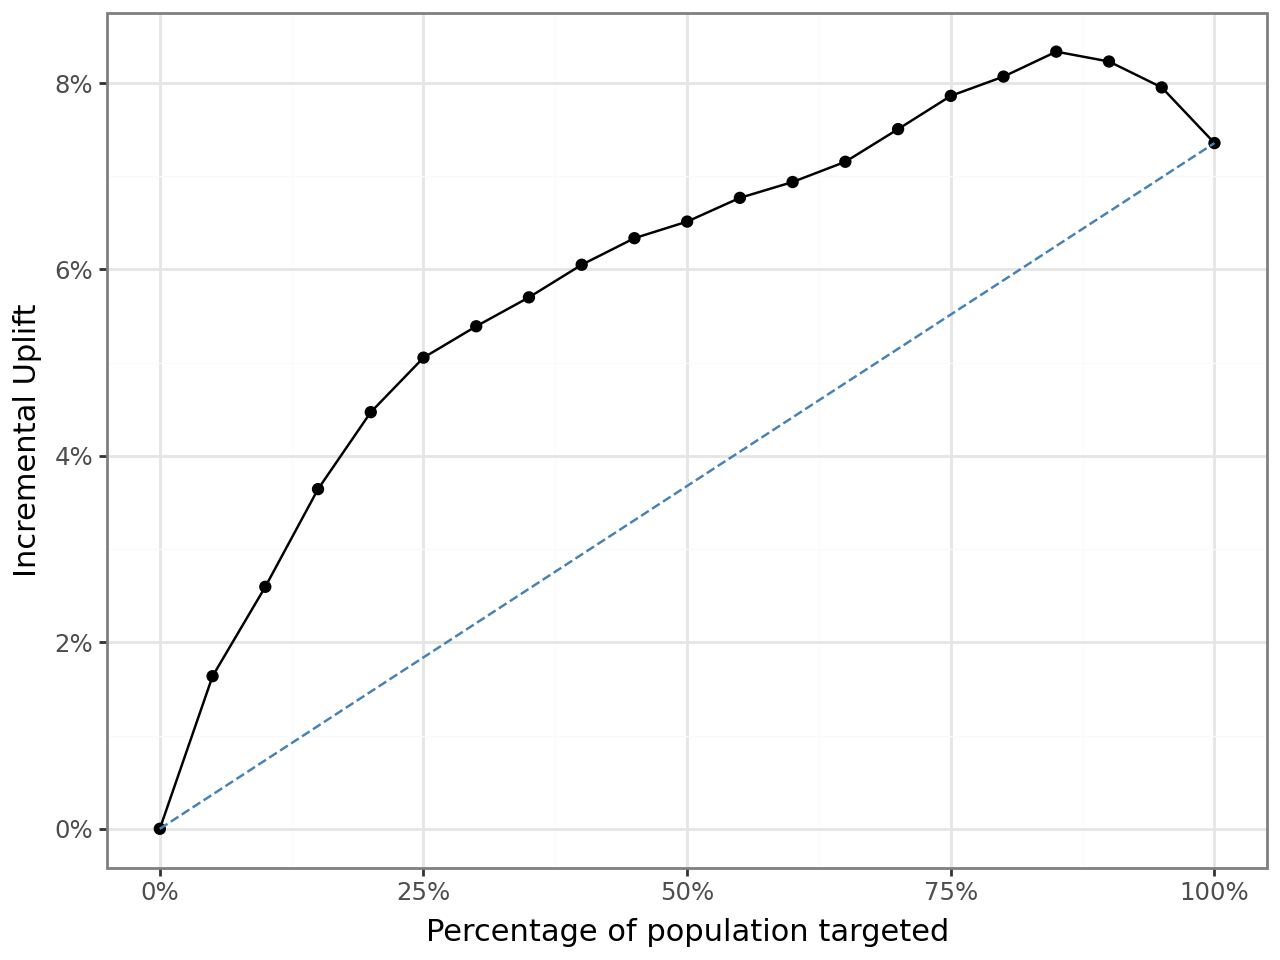

In [59]:
# Incremental Uplift Plot (20 Bins)

Uplift_Curve_Logit = rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),  # test data
    "converted",  # response variable
    "yes",  # positive class
    "uplift_score",  # prediction column
    "ad",  # treatment variable
    1,  # treatment level
    qnt=20,  # number of bins
)

Uplift_Curve_Logit.show()


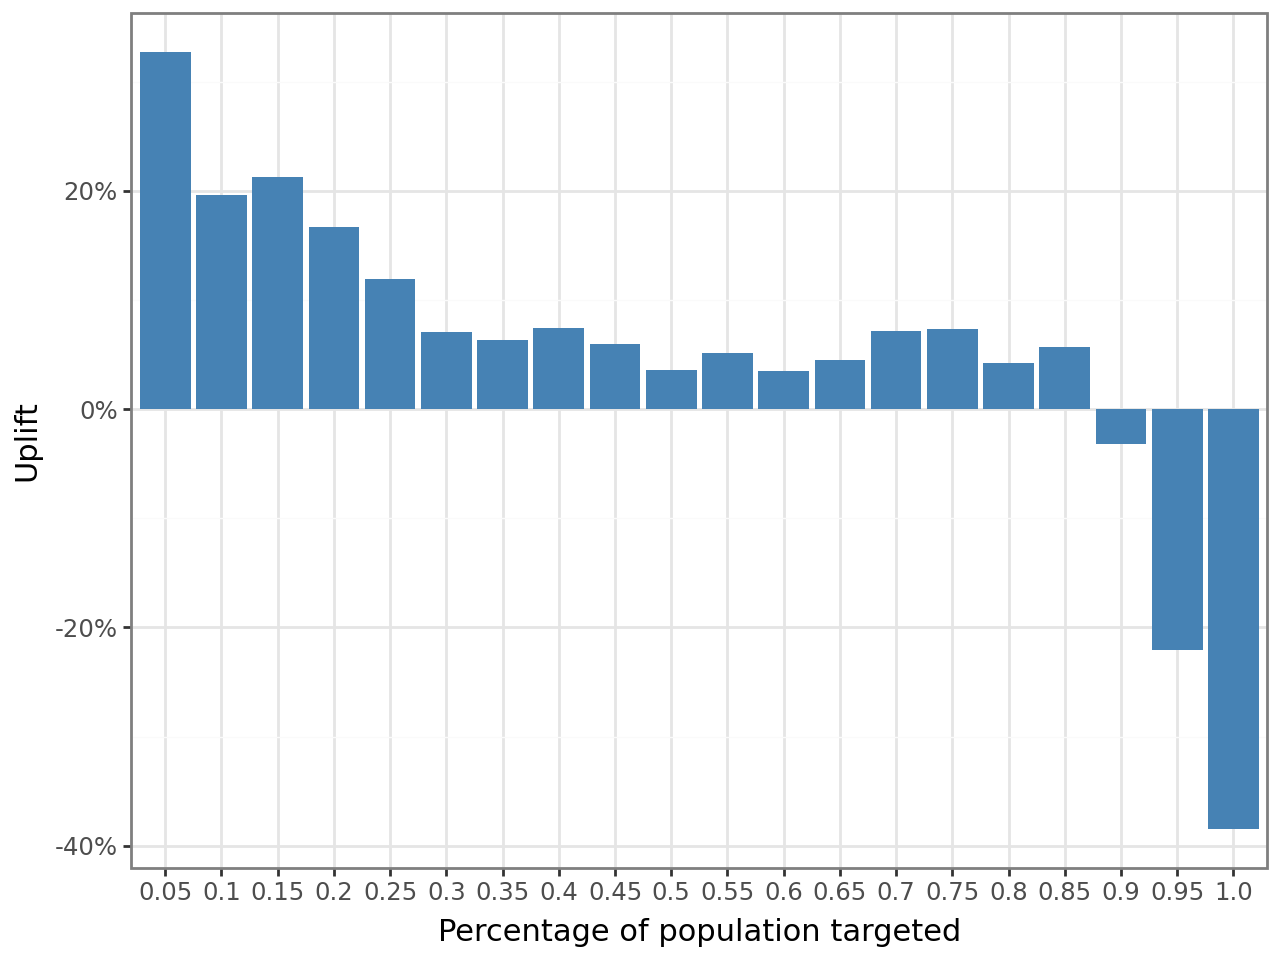

In [60]:
# Uplift Plot (Per Bin)

rsm.model.uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "uplift_score",
    "ad",
    1,
    qnt=20,
)


In [61]:
# Propensity Model
tab_prop = rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "pred_treatment",
    "ad",
    1,
    qnt=20,
)

tab_prop


pred,bins,cum_prop,T_resp,T_n,C_resp,C_n,incremental_resp,inc_uplift,uplift
str,i64,f64,u32,u32,u32,u32,f64,f64,f64
"""pred_treatment""",1,0.05,204,450,80,603,144.298507,1.603317,0.320663
"""pred_treatment""",2,0.1,326,900,112,1131,236.875332,2.631948,0.210505
"""pred_treatment""",3,0.15,430,1350,159,1605,296.261682,3.291796,0.131955
"""pred_treatment""",4,0.2,525,1800,206,1994,339.042126,3.767135,0.090288
"""pred_treatment""",5,0.25,615,2250,239,2344,385.584471,4.284272,0.105714
…,…,…,…,…,…,…,…,…,…
"""pred_treatment""",16,0.8,1065,7200,483,7256,585.727674,6.508085,0.064944
"""pred_treatment""",17,0.85,1091,7650,495,7649,595.935286,6.621503,0.027243
"""pred_treatment""",18,0.9,1120,8100,499,8093,620.568392,6.895204,0.055435


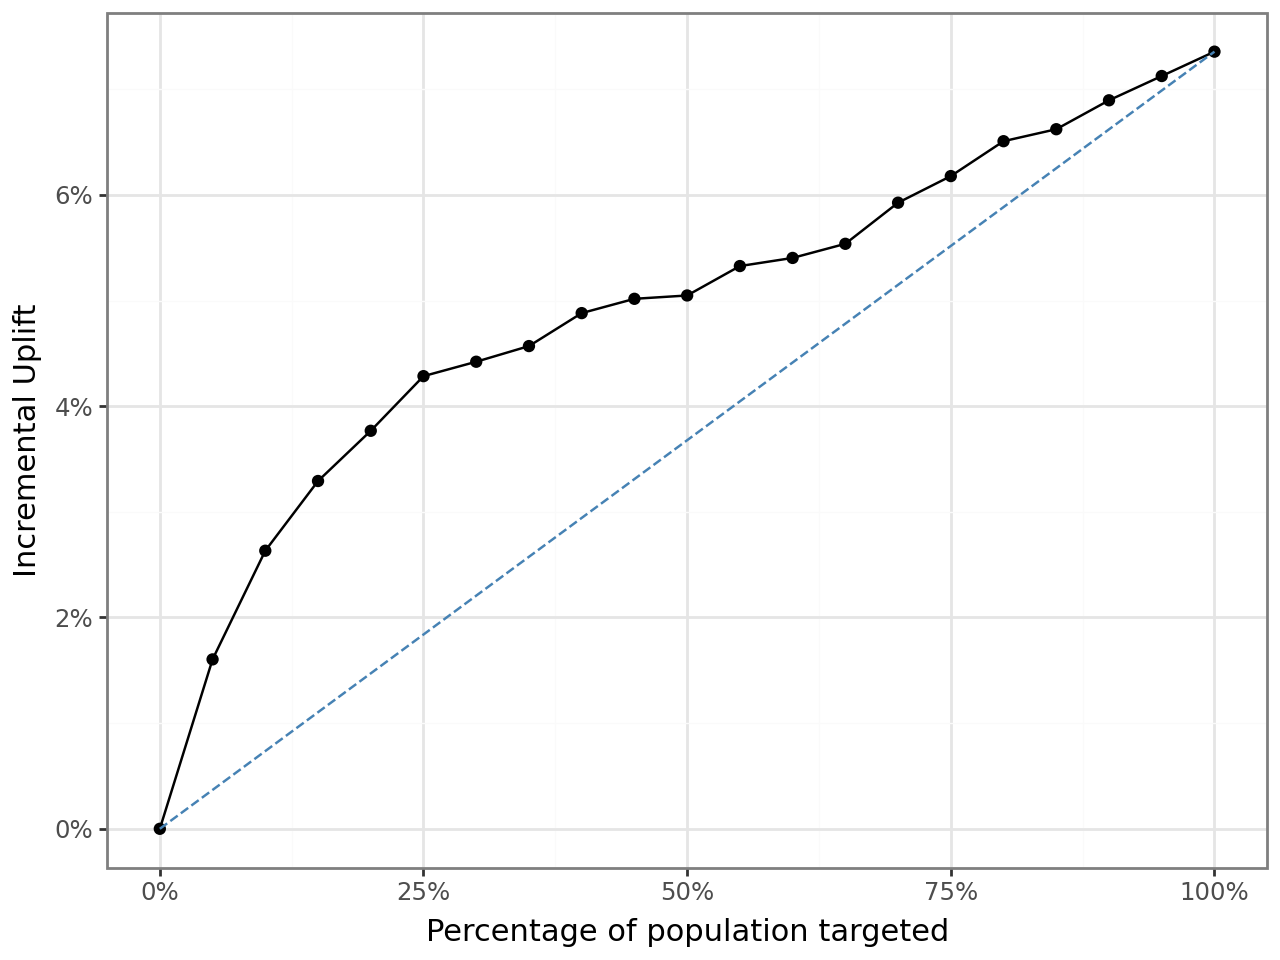

In [62]:
# Propensity Plot (Per Bin)

Propensity_Curve_Logit = rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "pred_treatment",
    "ad",
    1,
    qnt=20,
)

Propensity_Curve_Logit.show()


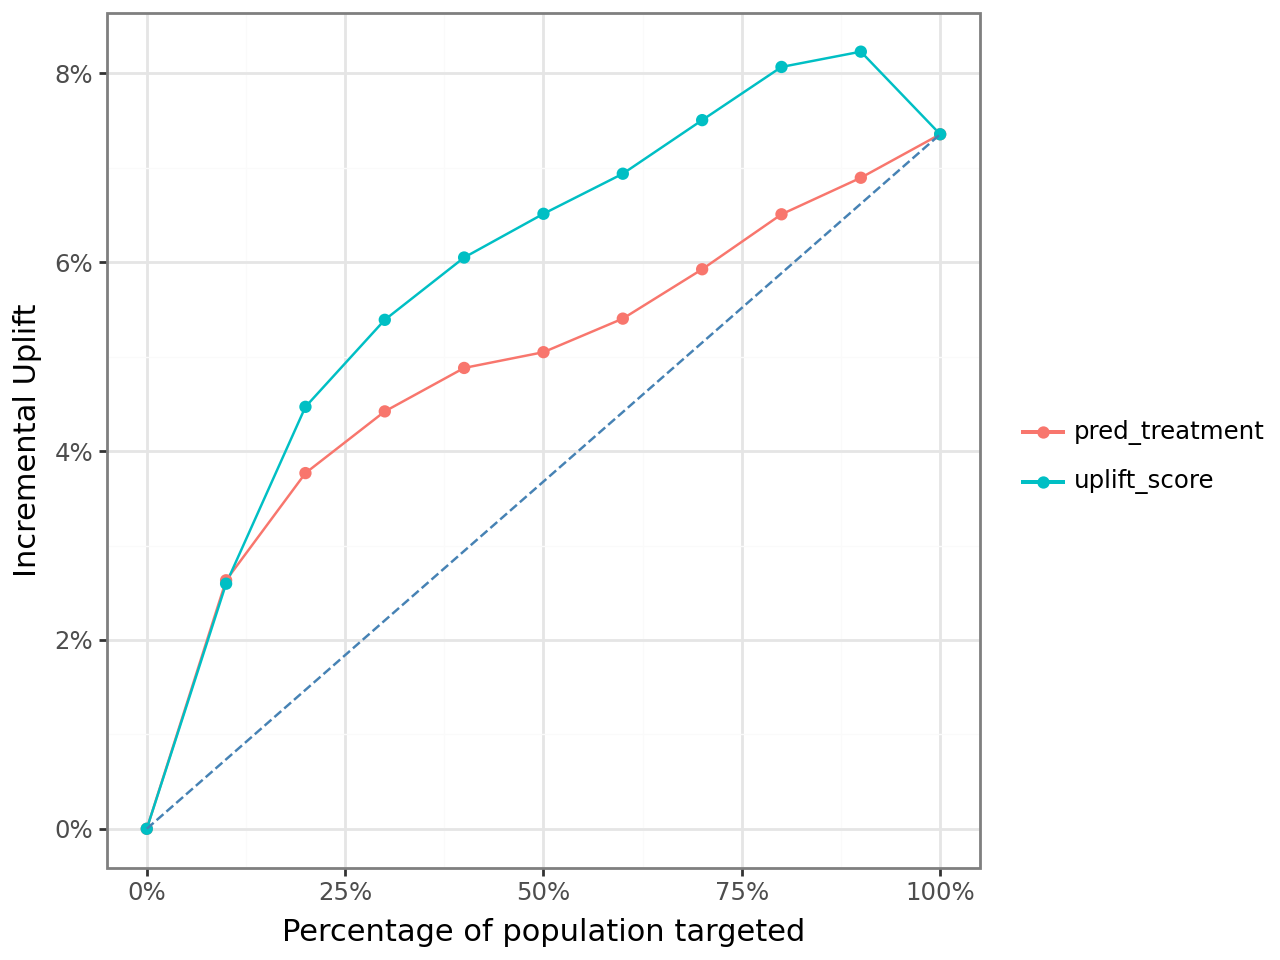

In [63]:
# Multi-Model Comparison

rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    ["pred_treatment", "uplift_score"],
    "ad",
    1,
)


In [64]:
# Incremental Profit (Uplift Model)

# SETTINGS
target_customers = 30_000
revenue = 14.99
cost_per_customer = 1.50

# 25% = bin 5
bin5 = tab.filter(pl.col("bins") == 5)

inc_resp_25_uplift = bin5.select("incremental_resp").item()
T_n = bin5.select("T_n").item()  # cumulative treated count up to bin 5

# Convert to incremental rate
inc_rate = inc_resp_25_uplift / T_n

# Scale correctly to deployment size
incremental_responders_uplift = inc_rate * target_customers

# Profit
incremental_revenue_uplift = incremental_responders_uplift * revenue
total_cost = target_customers * cost_per_customer
incremental_profit_uplift_log = incremental_revenue_uplift - total_cost

print("=== UPLIFT MODEL ===")
print("Customers Targeted:", target_customers)
print("Incremental Responders:", round(incremental_responders_uplift, 2))
print("Incremental Profit:", round(incremental_profit_uplift_log, 2))


=== UPLIFT MODEL ===
Customers Targeted: 30000
Incremental Responders: 6064.56
Incremental Profit: 45907.76


In [65]:
# Incremental Profit (Uplift Model)

# SETTINGS
target_customers = 30_000
revenue = 14.99
cost_per_customer = 1.50

# 25% = bin 5
bin5 = tab.filter(pl.col("bins") == 5)

# Extract correct values
inc_resp_25_uplift = bin5.select("incremental_resp").item()
T_n = bin5.select("T_n").item()  # treated count up to bin 5

# Step 1: Get incremental rate for that bin
inc_rate = inc_resp_25_uplift / T_n

# Step 2: Scale properly to deployment size
incremental_responders_uplift = inc_rate * target_customers

# Profit
incremental_revenue_uplift = incremental_responders_uplift * revenue
total_cost = target_customers * cost_per_customer
incremental_profit_prop_log = incremental_revenue_uplift - total_cost

print("=== UPLIFT MODEL ===")
print("Customers Targeted:", target_customers)
print("Incremental Responders:", round(incremental_responders_uplift, 2))
print("Incremental Profit:", round(incremental_profit_prop_log, 2))


=== UPLIFT MODEL ===
Customers Targeted: 30000
Incremental Responders: 6064.56
Incremental Profit: 45907.76


### MLP MODEL


In [66]:
# MLP Model — Treatment Group

clf_treatment_mlp = rsm.model.mlp(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 1)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
    hidden_layer_sizes=(1,),
    activation="relu",
    solver="lbfgs",
    alpha=0.01,
    max_iter=100_000,
    random_state=1234,
)

clf_treatment_mlp.summary()


Multi-layer Perceptron (NN)
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
Model type           : classification
Nr. of features      : (19, 19)
Nr. of weights       : 22
Nr. of observations  : 21,000
Hidden_layer_sizes   : (1,)
Activation function  : relu
Solver               : lbfgs
Alpha                : 0.01
Batch size           : auto
Learning rate        : 0.001
Maximum iterations   : 100000
random_state         : 1234
AUC                  : 0.712

Raw data             :
shape: (5, 19)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬──────────┬───────────┬───────────┐
│ Game

In [67]:
# MLP Model — Control Group

clf_control_mlp = rsm.model.mlp(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 0)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
    hidden_layer_sizes=(1,),
    activation="relu",
    solver="lbfgs",
    alpha=0.01,
    max_iter=100_000,
    random_state=1234,
)

clf_control_mlp.summary()


Multi-layer Perceptron (NN)
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
Model type           : classification
Nr. of features      : (19, 19)
Nr. of weights       : 22
Nr. of observations  : 21,000
Hidden_layer_sizes   : (1,)
Activation function  : relu
Solver               : lbfgs
Alpha                : 0.01
Batch size           : auto
Learning rate        : 0.001
Maximum iterations   : 100000
random_state         : 1234
AUC                  : 0.841

Raw data             :
shape: (5, 19)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬──────────┬───────────┬───────────┐
│ Game

In [68]:
import os
import numpy as np
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neural_network import MLPClassifier


In [69]:
# Cross Validation for MLP Treatment Model

cv_file_t = "cv-objects/mlp_cv_treatment.pkl"

# -----------------------------------
# Load if exists
# -----------------------------------
if os.path.exists(cv_file_t):
    cv_treat = rsm.notebook.load_state(cv_file_t)["cv_t"]
    print("Loaded saved treatment CV.")

    if not hasattr(cv_treat, "best_params_"):
        print("Invalid object. Re-running...")
        os.remove(cv_file_t)
        cv_treat = None
else:
    cv_treat = None


# -----------------------------------
# Run CV if needed
# -----------------------------------
if cv_treat is None:
    print("Running treatment grid search...")

    hls = [(i, j) for i in range(1, 6) for j in range(1, 6)]

    param_grid = {
        "hidden_layer_sizes": hls,
        "alpha": [0.0001, 0.001, 0.01, 0.1],
    }

    cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

    cv_treat = GridSearchCV(
        estimator=clf_treatment_mlp.fitted,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv_strat,
        refit=True,
        verbose=1,
        n_jobs=4,
    )

    cv_treat.fit(
        clf_treatment_mlp.data_onehot,
        clf_treatment_mlp.data.get_column("converted"),
    )

    if not os.path.exists("cv-objects"):
        os.mkdir("cv-objects")

    rsm.notebook.save_state({"cv_t": cv_treat}, cv_file_t)

    print("Treatment CV complete and saved.")


print("Best Treatment Params:", cv_treat.best_params_)
print("Best Treatment CV AUC:", cv_treat.best_score_)


Loaded saved treatment CV.
Best Treatment Params: {'alpha': np.float64(0.1), 'hidden_layer_sizes': (5, 4)}
Best Treatment CV AUC: 0.7807183097333146


In [70]:
# Cross Validation for MLP Control Model

cv_file_c = "cv-objects/mlp_cv_control.pkl"

# -----------------------------------
# Load if exists
# -----------------------------------
if os.path.exists(cv_file_c):
    loaded_obj = rsm.notebook.load_state(cv_file_c)

    # Try correct key first
    if "cv_c" in loaded_obj:
        cv_control = loaded_obj["cv_c"]
    # Fallback if previously saved incorrectly
    elif "cv_t" in loaded_obj:
        cv_control = loaded_obj["cv_t"]
    else:
        cv_control = None

    print("Loaded saved control CV.")

    if cv_control is None or not hasattr(cv_control, "best_params_"):
        print("Invalid object. Re-running...")
        os.remove(cv_file_c)
        cv_control = None
else:
    cv_control = None


# -----------------------------------
# Run CV if needed
# -----------------------------------
if cv_control is None:
    print("Running control grid search...")

    hls = [(i, j) for i in range(1, 6) for j in range(1, 6)]

    param_grid = {
        "hidden_layer_sizes": hls,
        "alpha": [0.0001, 0.001, 0.01, 0.1],
    }

    cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

    cv_control = GridSearchCV(
        estimator=clf_control_mlp.fitted,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv_strat,
        refit=True,
        verbose=1,
        n_jobs=4,
    )

    cv_control.fit(
        clf_control_mlp.data_onehot, clf_control_mlp.data.get_column("converted")
    )

    if not os.path.exists("cv-objects"):
        os.mkdir("cv-objects")

    # ✅ Save correctly now
    rsm.notebook.save_state({"cv_c": cv_control}, cv_file_c)

    print("Control CV complete and saved.")


print("Best Control Params:", cv_control.best_params_)
print("Best Control CV AUC:", cv_control.best_score_)


Loaded saved control CV.
Best Control Params: {'alpha': 0.001, 'hidden_layer_sizes': (5, 1)}
Best Control CV AUC: 0.8646192844523515


In [71]:
# Tuned MLP Model — Treatment Group

clf_treatment_mlp_tuned = rsm.model.mlp(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 1)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
    random_state=1234,
    activation="relu",
    **cv_treat.best_params_,  # 🔥 automatically inserts best alpha & HLS
)

clf_treatment_mlp_tuned.summary()


Multi-layer Perceptron (NN)
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
Model type           : classification
Nr. of features      : (19, 19)
Nr. of weights       : 129
Nr. of observations  : 21,000
Hidden_layer_sizes   : (5, 4)
Activation function  : relu
Solver               : lbfgs
Alpha                : 0.1
Batch size           : auto
Learning rate        : 0.001
Maximum iterations   : 1000000
random_state         : 1234
AUC                  : 0.799

Raw data             :
shape: (5, 19)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬──────────┬───────────┬───────────┐
│ G

In [72]:
# Tuned MLP Model — Control Group

clf_control_mlp_tuned = rsm.model.mlp(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 0)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
    random_state=1234,
    **cv_control.best_params_,  # 🔥 plugs (5,1) and alpha=0.001
)

clf_control_mlp_tuned.summary()


Multi-layer Perceptron (NN)
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
Model type           : classification
Nr. of features      : (19, 19)
Nr. of weights       : 108
Nr. of observations  : 21,000
Hidden_layer_sizes   : (5, 1)
Activation function  : tanh
Solver               : lbfgs
Alpha                : 0.001
Batch size           : auto
Learning rate        : 0.001
Maximum iterations   : 1000000
random_state         : 1234
AUC                  : 0.87

Raw data             :
shape: (5, 19)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬──────────┬───────────┬───────────┐
│ 

In [73]:
# Generate Tuned Predictions

cg_rct_stacked = cg_rct_stacked.with_columns(
    [
        pl.Series(
            "pred_treatment_mlp_tuned",
            clf_treatment_mlp_tuned.predict(cg_rct_stacked)["prediction"],
        ),
        pl.Series(
            "pred_control_mlp_tuned",
            clf_control_mlp_tuned.predict(cg_rct_stacked)["prediction"],
        ),
    ]
)


In [74]:
# Create Tuned Uplift Score

cg_rct_stacked = cg_rct_stacked.with_columns(
    (pl.col("pred_treatment_mlp_tuned") - pl.col("pred_control_mlp_tuned")).alias(
        "uplift_score_mlp_tuned"
    )
)


In [75]:
# Tuned MLP Uplift Table
rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "uplift_score_mlp_tuned",
    "ad",
    1,
    qnt=20,
)


pred,bins,cum_prop,T_resp,T_n,C_resp,C_n,incremental_resp,inc_uplift,uplift
str,i64,f64,u32,u32,u32,u32,f64,f64,f64
"""uplift_score_mlp_tuned""",1,0.05,208,450,65,607,159.812191,1.775691,0.355138
"""uplift_score_mlp_tuned""",2,0.1,363,900,105,1094,276.619744,3.073553,0.262309
"""uplift_score_mlp_tuned""",3,0.15,502,1350,148,1616,378.361386,4.204015,0.226513
"""uplift_score_mlp_tuned""",4,0.2,623,1800,186,2118,464.926346,5.165848,0.193192
"""uplift_score_mlp_tuned""",5,0.25,688,2250,211,2672,510.324102,5.670268,0.099318
…,…,…,…,…,…,…,…,…,…
"""uplift_score_mlp_tuned""",16,0.8,1033,7200,313,7801,744.11396,8.267933,0.010226
"""uplift_score_mlp_tuned""",17,0.85,1055,7650,320,8221,757.226007,8.413622,0.032222
"""uplift_score_mlp_tuned""",18,0.9,1090,8100,356,8633,755.979381,8.399771,-0.009601


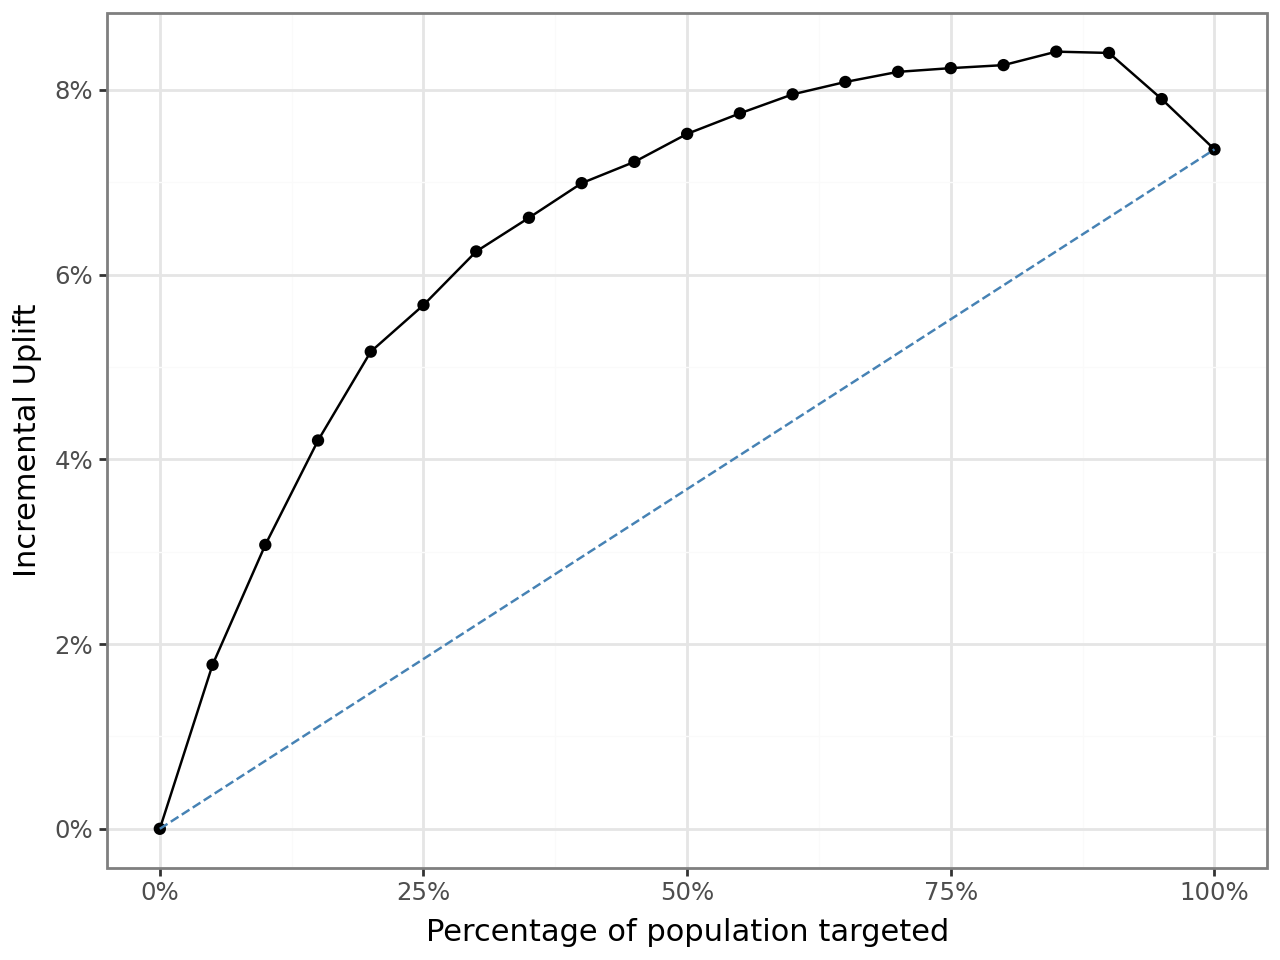

In [76]:
# Uplift Plot for Tuned MLP

Uplift_Curve_MLP = rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "uplift_score_mlp_tuned",
    "ad",
    1,
    qnt=20,
)

Uplift_Curve_MLP.show()

In [77]:
# Tuned MLP Propensity Table
rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "pred_control_mlp_tuned",
    "ad",
    1,
    qnt=20,
)


pred,bins,cum_prop,T_resp,T_n,C_resp,C_n,incremental_resp,inc_uplift,uplift
str,i64,f64,u32,u32,u32,u32,f64,f64,f64
"""pred_control_mlp_tuned""",1,0.05,38,450,65,156,-149.5,-1.661111,-0.332222
"""pred_control_mlp_tuned""",2,0.1,97,900,148,360,-273.0,-3.033333,-0.275752
"""pred_control_mlp_tuned""",3,0.15,220,1350,244,742,-223.93531,-2.48817,0.022024
"""pred_control_mlp_tuned""",4,0.2,364,1800,295,1274,-52.797488,-0.586639,0.224135
"""pred_control_mlp_tuned""",5,0.25,474,2250,343,1775,39.211268,0.435681,0.148636
…,…,…,…,…,…,…,…,…,…
"""pred_control_mlp_tuned""",16,0.8,1082,7200,493,7216,590.093126,6.55659,0.057096
"""pred_control_mlp_tuned""",17,0.85,1104,7650,503,7688,603.486212,6.705402,0.027702
"""pred_control_mlp_tuned""",18,0.9,1128,8100,508,8144,622.744597,6.919384,0.042368


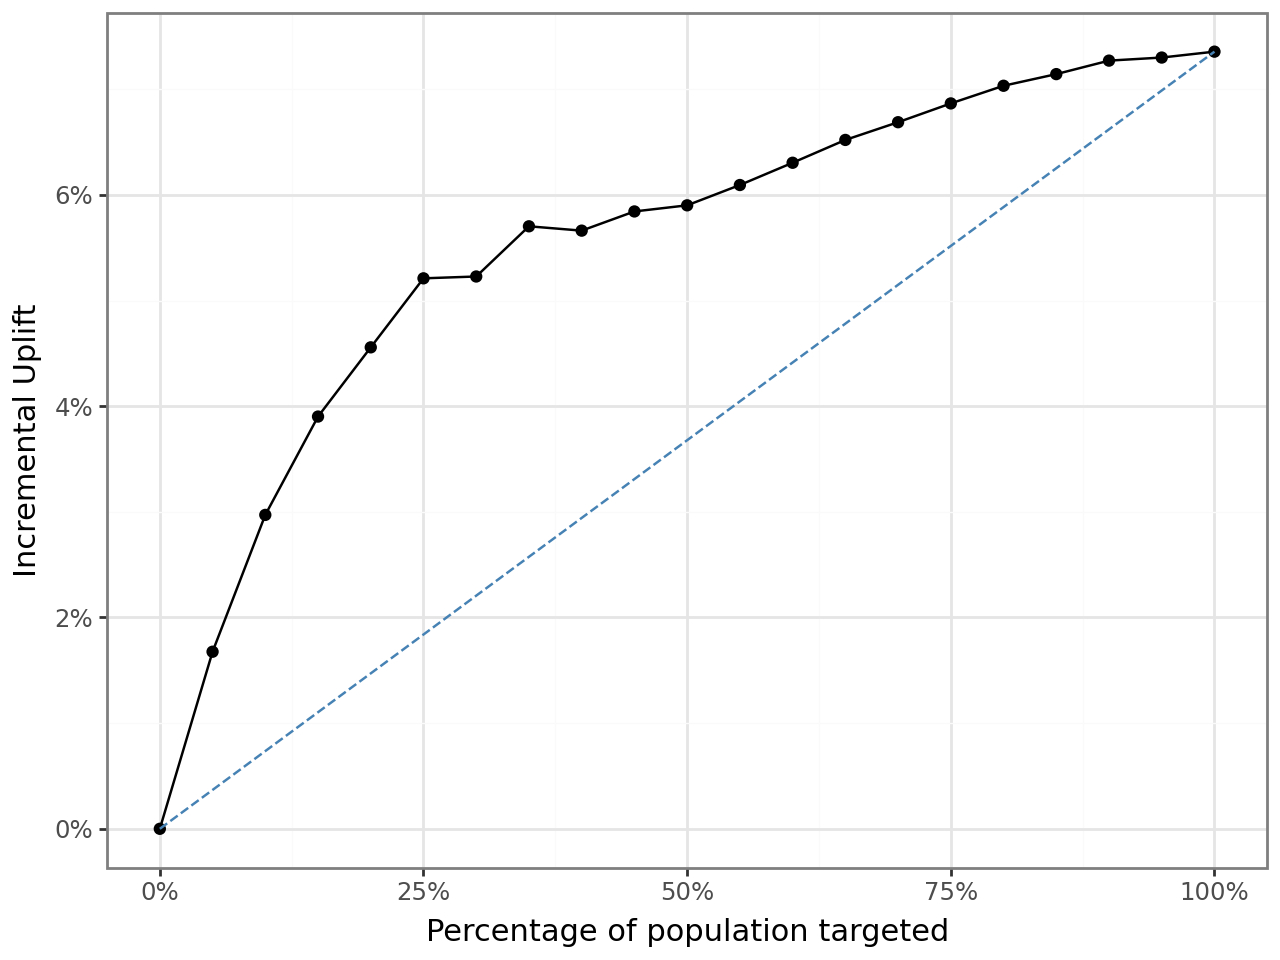

In [78]:
# Tuned MLP Propensity Plot

Propensity_Curve_MLP = rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "pred_treatment_mlp_tuned",
    "ad",
    1,
    qnt=20,
)

Propensity_Curve_MLP.show()

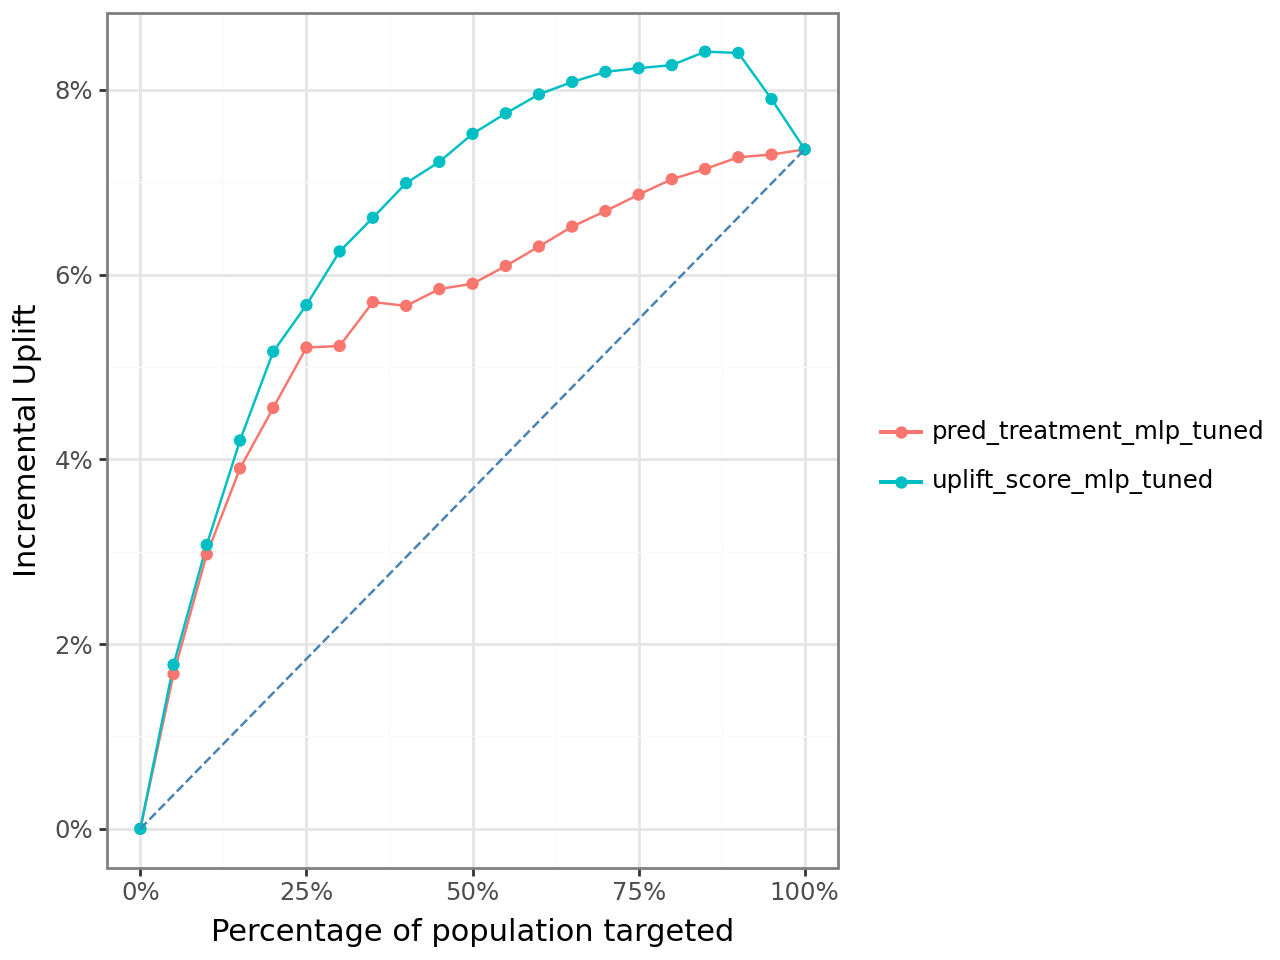

In [79]:
# Multi-Model Comparison

rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    [
        "pred_treatment_mlp_tuned",  # MLP propensity
        "uplift_score_mlp_tuned",  # MLP uplift
    ],
    "ad",
    1,
    qnt=20,
)


In [80]:
# Incremental Profit (Tuned MLP Uplift Model)

target_customers = 30_000
treated_experiment = 9_000
revenue = 14.99
cost_per_customer = 1.50

# Create uplift table for tuned MLP
tab_mlp = rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "uplift_score_mlp_tuned",
    "ad",
    1,
    qnt=20,
)

# 25% targeting → bin 5
bin5_mlp = tab_mlp.filter(pl.col("bins") == 5)

# Extract correct values
inc_resp_25_mlp = bin5_mlp.select("incremental_resp").item()
T_n_mlp = bin5_mlp.select("T_n").item()  # treated count up to bin 5

# Step 1: Compute incremental rate
inc_rate_mlp = inc_resp_25_mlp / T_n_mlp

# Step 2: Scale correctly to deployment size
incremental_responders_mlp = inc_rate_mlp * target_customers

# Profit
incremental_revenue_mlp = incremental_responders_mlp * revenue
total_cost_mlp = target_customers * cost_per_customer
incremental_profit_mlp = incremental_revenue_mlp - total_cost_mlp

print("=== MLP UPLIFT MODEL ===")
print("Customers Targeted:", target_customers)
print("Incremental Responders:", round(incremental_responders_mlp, 2))
print("Incremental Profit:", round(incremental_profit_mlp, 2))


=== MLP UPLIFT MODEL ===
Customers Targeted: 30000
Incremental Responders: 6804.32
Incremental Profit: 56996.78


In [81]:
# Incremental Profit (Tuned MLP Propensity Model)

target_customers = 30_000
treated_experiment = 9_000
revenue = 14.99
cost_per_customer = 1.50

# Create propensity table for tuned MLP
tab_prop_mlp = rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "pred_treatment_mlp_tuned",
    "ad",
    1,
    qnt=20,
)

# 25% targeting → bin 5
bin5_prop_mlp = tab_prop_mlp.filter(pl.col("bins") == 5)

# Extract correct values
inc_resp_25_prop = bin5_prop_mlp.select("incremental_resp").item()
T_n_prop = bin5_prop_mlp.select("T_n").item()  # treated count up to bin 5

# Step 1: Compute incremental rate
inc_rate_prop = inc_resp_25_prop / T_n_prop

# Step 2: Scale correctly to deployment
incremental_responders_prop = inc_rate_prop * target_customers

# Profit
incremental_revenue_prop = incremental_responders_prop * revenue
total_cost_prop = target_customers * cost_per_customer
incremental_profit_prop_mlp = incremental_revenue_prop - total_cost_prop

print("=== MLP PROPENSITY MODEL ===")
print("Customers Targeted:", target_customers)
print("Incremental Responders:", round(incremental_responders_prop, 2))
print("Incremental Profit:", round(incremental_profit_prop_mlp, 2))


=== MLP PROPENSITY MODEL ===
Customers Targeted: 30000
Incremental Responders: 6252.12
Incremental Profit: 48719.33


### RANDOM FOREST

In [82]:
# Baseline RF — Treatment
clf_treat_rf_base = rsm.model.rforest(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 1)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
    n_estimators=200,
    random_state=1234,
)
clf_treat_rf_base.summary()

Random Forest
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
OOB                  : True
Model type           : classification
Nr. of features      : (19, 19)
Nr. of observations  : 21,000
max_features         : sqrt (4)
n_estimators         : 200
min_samples_leaf     : 1
max_samples          : 1.0
random_state         : 1234
AUC                  : 0.765

Estimation data      :
shape: (5, 19)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ GameLevel ┆ NumGameDa ┆ NumGameDa ┆ NumInGame ┆ … ┆ Purchased ┆ Purchased ┆ UserConso ┆ UserHasO │
│ --- 

In [83]:
# Baseline RF — Control
clf_ctrl_rf_base = rsm.model.rforest(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 0)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
    n_estimators=200,
    random_state=1234,
)

clf_ctrl_rf_base.summary()


Random Forest
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
OOB                  : True
Model type           : classification
Nr. of features      : (19, 19)
Nr. of observations  : 21,000
max_features         : sqrt (4)
n_estimators         : 200
min_samples_leaf     : 1
max_samples          : 1.0
random_state         : 1234
AUC                  : 0.863

Estimation data      :
shape: (5, 19)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ GameLevel ┆ NumGameDa ┆ NumGameDa ┆ NumInGame ┆ … ┆ Purchased ┆ Purchased ┆ UserConso ┆ UserHasO │
│ --- 

In [84]:
# CROSS-VALIDATION FOR RF TREATMENT MODEL

cv_file_t = "cv-objects/rf_cv_treatment.pkl"

if os.path.exists(cv_file_t):
    rf_cv_t = list(rsm.notebook.load_state(cv_file_t).values())[0]
else:
    rf_cv_t = None

if rf_cv_t is None:
    print("Running RF treatment grid search...")

    param_grid = {
        "n_estimators": [200, 300, 500],
        "max_depth": [None, 5, 10],
        "min_samples_leaf": [1, 5, 10],
    }

    cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

    rf_cv_t = GridSearchCV(
        estimator=clf_treat_rf_base.fitted,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv_strat,
        refit=True,
        n_jobs=4,
        verbose=1,
    )

    rf_cv_t.fit(
        clf_treat_rf_base.data_onehot, clf_treat_rf_base.data.get_column("converted")
    )

    if not os.path.exists("cv-objects"):
        os.mkdir("cv-objects")

    rsm.notebook.save_state({"rf_cv_t": rf_cv_t}, cv_file_t)

print("Best RF Treatment Params:", rf_cv_t.best_params_)
print("Best RF Treatment CV AUC:", rf_cv_t.best_score_)


Best RF Treatment Params: {'max_depth': None, 'min_samples_leaf': 10, 'n_estimators': 500}
Best RF Treatment CV AUC: 0.78352245813211


In [85]:
# CROSS-VALIDATION FOR RF CONTROL MODEL

cv_file_c = "cv-objects/rf_cv_control.pkl"

if os.path.exists(cv_file_c):
    rf_cv_c = list(rsm.notebook.load_state(cv_file_c).values())[0]
else:
    rf_cv_c = None

if rf_cv_c is None:
    print("Running RF control grid search...")

    param_grid = {
        "n_estimators": [200, 300, 500],
        "max_depth": [None, 5, 10],
        "min_samples_leaf": [1, 5, 10],
    }

    cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

    rf_cv_c = GridSearchCV(
        estimator=clf_ctrl_rf_base.fitted,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv_strat,
        refit=True,
        n_jobs=4,
        verbose=1,
    )

    rf_cv_c.fit(
        clf_ctrl_rf_base.data_onehot, clf_ctrl_rf_base.data.get_column("converted")
    )

    if not os.path.exists("cv-objects"):
        os.mkdir("cv-objects")

    rsm.notebook.save_state({"rf_cv_c": rf_cv_c}, cv_file_c)

print("Best RF Control Params:", rf_cv_c.best_params_)
print("Best RF Control CV AUC:", rf_cv_c.best_score_)


Best RF Control Params: {'max_depth': None, 'min_samples_leaf': 10, 'n_estimators': 500}
Best RF Control CV AUC: 0.8814089621263961


In [86]:
# Tuned RF Model — Treatment Group

clf_treat_rf_tuned = rsm.model.rforest(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 1)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
    random_state=1234,
    **rf_cv_t.best_params_,
)

clf_treat_rf_tuned.summary()

Random Forest
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
OOB                  : True
Model type           : classification
Nr. of features      : (19, 19)
Nr. of observations  : 21,000
max_features         : sqrt (4)
n_estimators         : 500
min_samples_leaf     : 10
max_samples          : 1.0
random_state         : 1234
AUC                  : 0.784
Extra arguments      : max_depth=None

Estimation data      :
shape: (5, 19)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ GameLevel ┆ NumGameDa ┆ NumGameDa ┆ NumInGame ┆ … ┆ Purchased ┆ Pu

In [87]:
# Tuned RF Model — Control Group

clf_ctrl_rf_tuned = rsm.model.rforest(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 0)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
    random_state=1234,
    **rf_cv_c.best_params_,
)

clf_ctrl_rf_tuned.summary()


Random Forest
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
OOB                  : True
Model type           : classification
Nr. of features      : (19, 19)
Nr. of observations  : 21,000
max_features         : sqrt (4)
n_estimators         : 500
min_samples_leaf     : 10
max_samples          : 1.0
random_state         : 1234
AUC                  : 0.881
Extra arguments      : max_depth=None

Estimation data      :
shape: (5, 19)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ GameLevel ┆ NumGameDa ┆ NumGameDa ┆ NumInGame ┆ … ┆ Purchased ┆ Pu

In [88]:
# Generate Tuned RF Predictions

cg_rct_stacked = cg_rct_stacked.with_columns(
    [
        pl.Series(
            "pred_treat_rf_tuned",
            clf_treat_rf_tuned.predict(cg_rct_stacked)["prediction"],
        ),
        pl.Series(
            "pred_ctrl_rf_tuned",
            clf_ctrl_rf_tuned.predict(cg_rct_stacked)["prediction"],
        ),
    ]
)

cg_rct_stacked = cg_rct_stacked.with_columns(
    (pl.col("pred_treat_rf_tuned") - pl.col("pred_ctrl_rf_tuned")).alias(
        "uplift_rf_tuned"
    )
)


In [89]:
# Uplift Table for Tuned RF

tab_uplift_rf = rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "uplift_rf_tuned",
    "ad",
    1,
    qnt=20,
)

tab_uplift_rf

pred,bins,cum_prop,T_resp,T_n,C_resp,C_n,incremental_resp,inc_uplift,uplift
str,i64,f64,u32,u32,u32,u32,f64,f64,f64
"""uplift_rf_tuned""",1,0.05,218,450,71,625,166.88,1.854222,0.370844
"""uplift_rf_tuned""",2,0.1,349,900,101,1143,269.472441,2.994138,0.233196
"""uplift_rf_tuned""",3,0.15,470,1350,127,1648,365.964806,4.066276,0.217404
"""uplift_rf_tuned""",4,0.2,581,1800,152,2192,456.182482,5.068694,0.200711
"""uplift_rf_tuned""",5,0.25,664,2250,183,2776,515.675072,5.729723,0.131362
…,…,…,…,…,…,…,…,…,…
"""uplift_rf_tuned""",16,0.8,1034,7200,299,7897,761.390148,8.459891,0.019438
"""uplift_rf_tuned""",17,0.85,1043,7650,302,8316,765.186147,8.502068,0.01284
"""uplift_rf_tuned""",18,0.9,1087,8100,360,8665,750.473745,8.338597,-0.068411


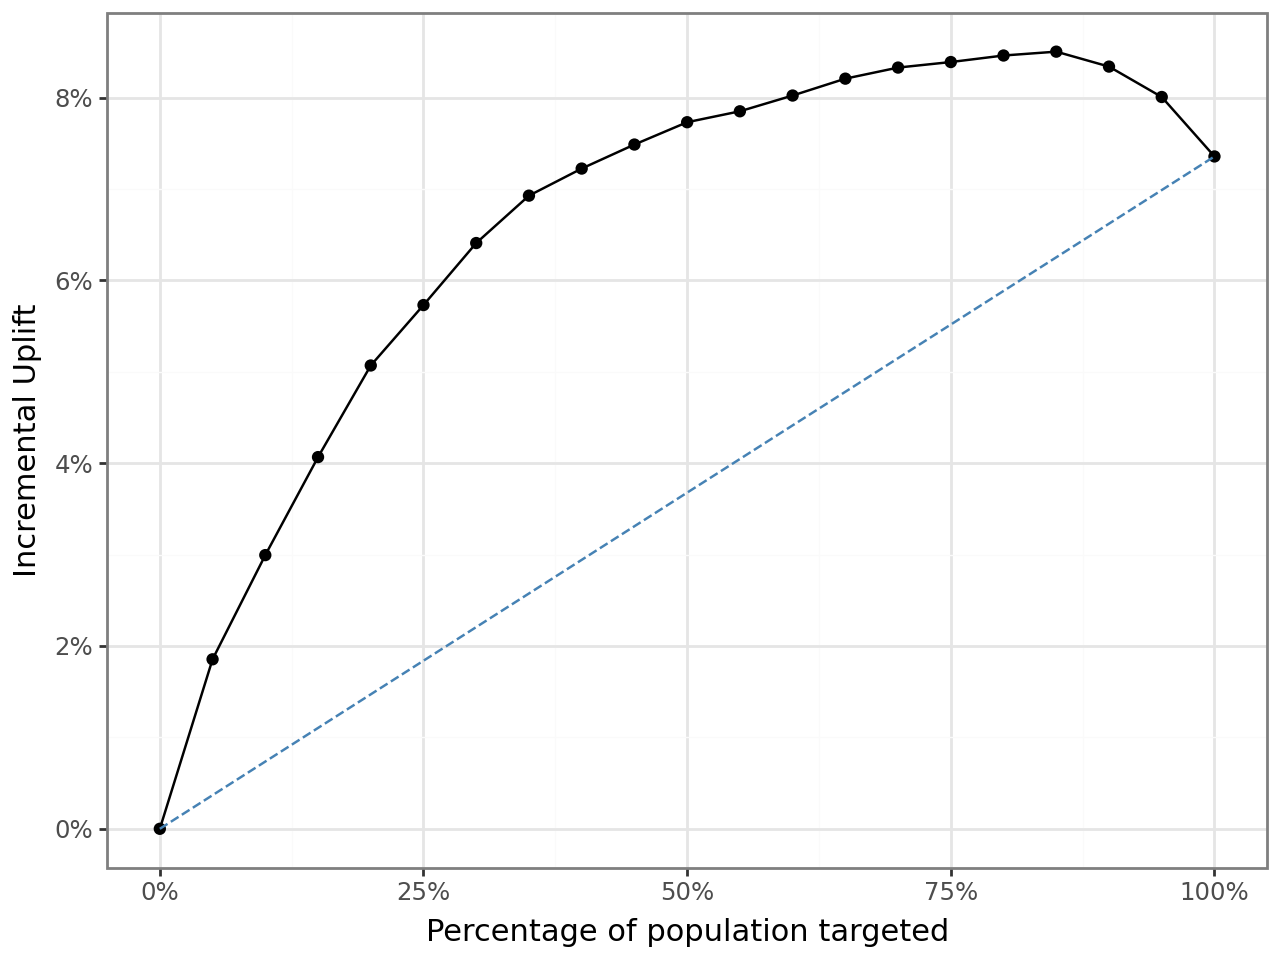

In [90]:
# Uplift Plot for Tuned RF

Uplift_Curve_RF = rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "uplift_rf_tuned",  # RF uplift score
    "ad",
    1,
    qnt=20,
)

Uplift_Curve_RF.show()

In [91]:
# Propensity Table for Tuned RF

tab_prop_rf = rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "pred_treat_rf_tuned",
    "ad",
    1,
    qnt=20,
)

tab_prop_rf

pred,bins,cum_prop,T_resp,T_n,C_resp,C_n,incremental_resp,inc_uplift,uplift
str,i64,f64,u32,u32,u32,u32,f64,f64,f64
"""pred_treat_rf_tuned""",1,0.05,223,450,82,614,162.90228,1.810025,0.362005
"""pred_treat_rf_tuned""",2,0.1,368,900,118,1094,270.925046,3.010278,0.247222
"""pred_treat_rf_tuned""",3,0.15,507,1350,170,1569,360.728489,4.008094,0.199415
"""pred_treat_rf_tuned""",4,0.2,618,1800,218,2048,426.398438,4.73776,0.146458
"""pred_treat_rf_tuned""",5,0.25,705,2250,269,2493,462.220217,5.13578,0.078727
…,…,…,…,…,…,…,…,…,…
"""pred_treat_rf_tuned""",16,0.8,1136,7200,507,7283,634.777976,7.053089,0.022397
"""pred_treat_rf_tuned""",17,0.85,1146,7650,508,7740,643.906977,7.154522,0.020034
"""pred_treat_rf_tuned""",18,0.9,1157,8100,510,8169,651.307749,7.236753,0.019782


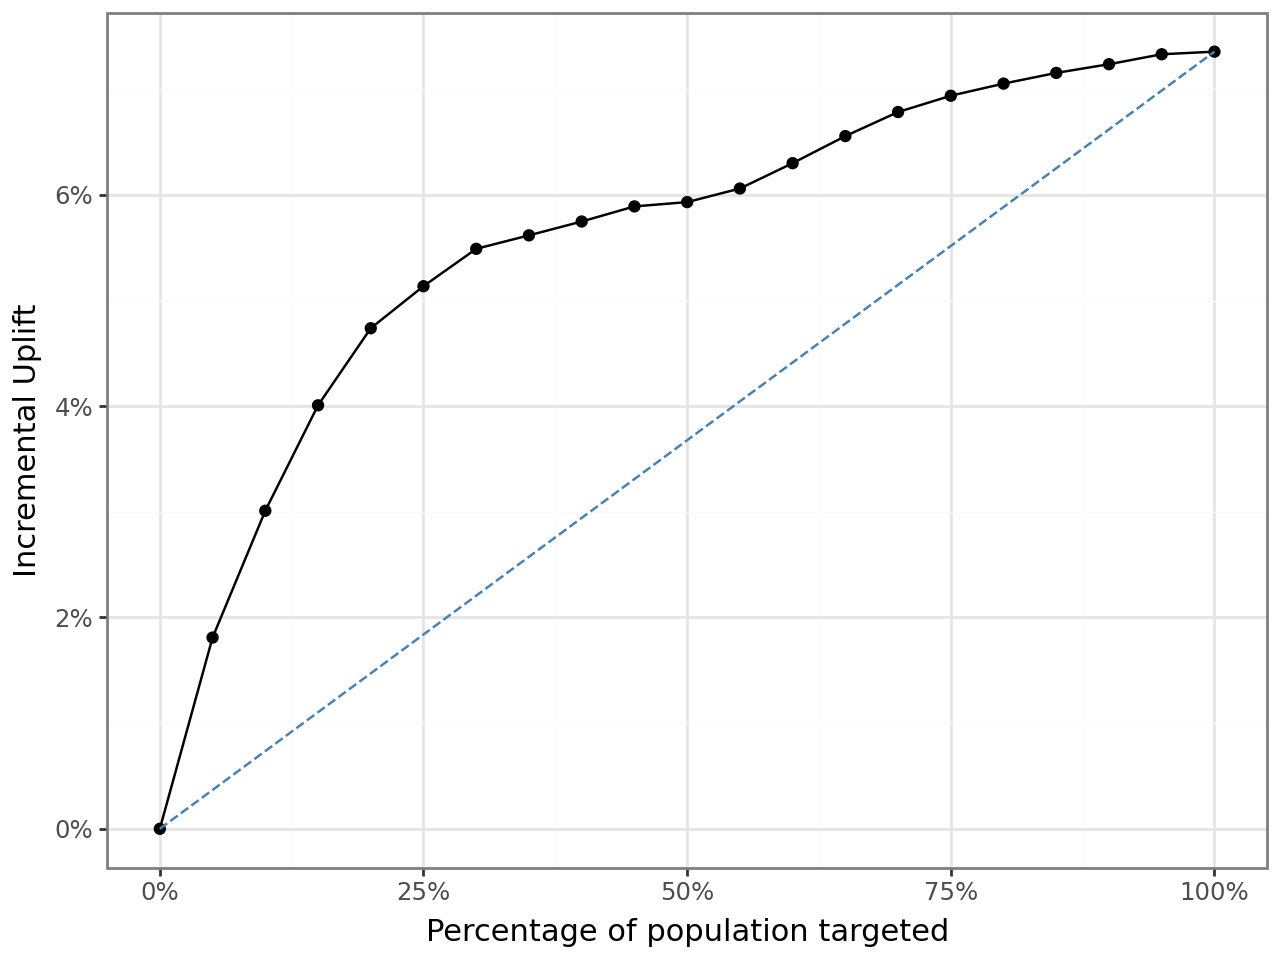

In [92]:
# Propensity plot for Tuned RF

Propensity_Curve_RF = rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "pred_treat_rf_tuned",  # RF treatment probability
    "ad",
    1,
    qnt=20,
)

Propensity_Curve_RF.show()

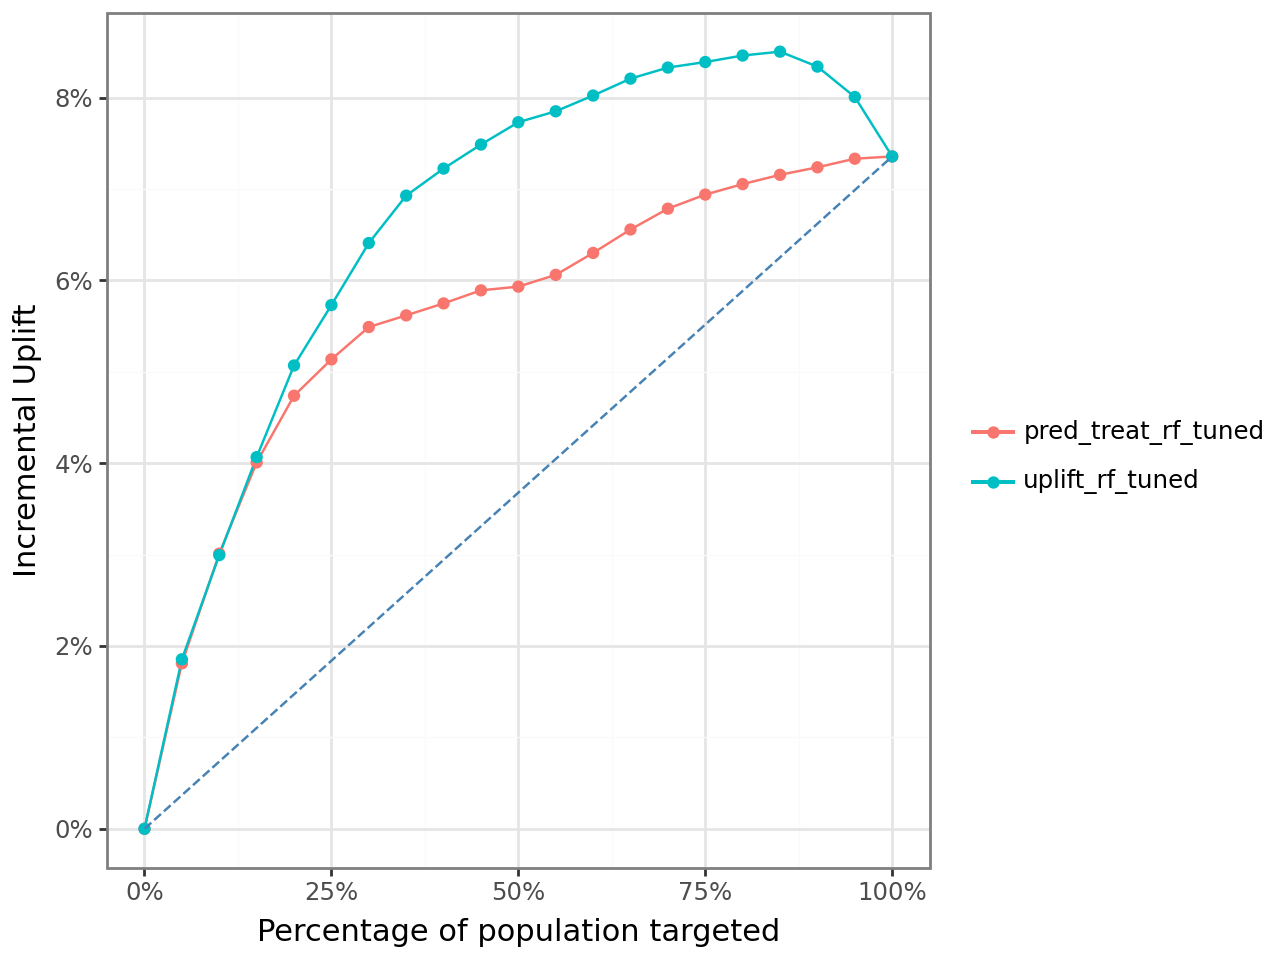

In [93]:
# Model Comparison Plot for Tuned RF

rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    [
        "pred_treat_rf_tuned",  # RF propensity
        "uplift_rf_tuned",  # RF uplift
    ],
    "ad",
    1,
    qnt=20,
)


In [94]:
# Incremental Profit (RF Uplift Model)

target_customers = 30_000
treated_experiment = 9_000
revenue = 14.99
cost_per_customer = 1.50

# Build uplift table (test only)
tab_rf_uplift = rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "uplift_rf_tuned",
    "ad",
    1,
    qnt=20,
)

# 25% targeting = bin 5
bin5_rf = tab_rf_uplift.filter(pl.col("bins") == 5)

# Extract correct values
inc_resp_rf = bin5_rf.select("incremental_resp").item()
T_n_rf = bin5_rf.select("T_n").item()  # treated count up to bin 5

# Step 1: Compute incremental rate
inc_rate_rf = inc_resp_rf / T_n_rf

# Step 2: Scale correctly to deployment
incremental_responders_rf = inc_rate_rf * target_customers

# Profit
incremental_revenue_rf = incremental_responders_rf * revenue
total_cost_rf = target_customers * cost_per_customer
incremental_profit_rf = incremental_revenue_rf - total_cost_rf

print("=== RANDOM FOREST UPLIFT MODEL ===")
print("Customers Targeted:", target_customers)
print("Incremental Responders:", round(incremental_responders_rf, 2))
print("Incremental Profit:", round(incremental_profit_rf, 2))


=== RANDOM FOREST UPLIFT MODEL ===
Customers Targeted: 30000
Incremental Responders: 6875.67
Incremental Profit: 58066.26


In [95]:
# Incremental Profit (RF Propensity Model)

target_customers = 30_000
treated_experiment = 9_000
revenue = 14.99
cost_per_customer = 1.50

# Build propensity table (test only)
tab_rf_prop = rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "pred_treat_rf_tuned",
    "ad",
    1,
    qnt=20,
)

# 25% targeting = bin 5
bin5_rf_prop = tab_rf_prop.filter(pl.col("bins") == 5)

# Extract correct values
inc_resp_rf_prop = bin5_rf_prop.select("incremental_resp").item()
T_n_rf_prop = bin5_rf_prop.select("T_n").item()  # treated count up to bin 5

# Step 1: Compute incremental rate
inc_rate_rf_prop = inc_resp_rf_prop / T_n_rf_prop

# Step 2: Scale correctly to deployment size
incremental_responders_rf_prop = inc_rate_rf_prop * target_customers

# Profit
incremental_revenue_rf_prop = incremental_responders_rf_prop * revenue
total_cost_rf_prop = target_customers * cost_per_customer
incremental_profit_rf_prop = incremental_revenue_rf_prop - total_cost_rf_prop

print("=== RANDOM FOREST PROPENSITY MODEL ===")
print("Customers Targeted:", target_customers)
print("Incremental Responders:", round(incremental_responders_rf_prop, 2))
print("Incremental Profit:", round(incremental_profit_rf_prop, 2))


=== RANDOM FOREST PROPENSITY MODEL ===
Customers Targeted: 30000
Incremental Responders: 6162.94
Incremental Profit: 47382.41


### XGBOOST

In [96]:
# Baseline XGBoost — Treatment
clf_treat_xgb_base = rsm.model.xgboost(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 1)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,
    random_state=1234,
)

clf_treat_xgb_base.summary()

XGBoost
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
Model type           : classification
Nr. of features      : (19, 19)
Nr. of observations  : 21,000
n_estimators         : 300
max_depth            : 4
min_child_weight     : 1
learning_rate        : 0.1
subsample            : 1.0
colsample_bytree     : 1.0
random_state         : 1234
AUC                  : 0.875

Estimation data      :
shape: (5, 19)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ GameLevel ┆ NumGameDa ┆ NumGameDa ┆ NumInGame ┆ … ┆ Purchased ┆ Purchased ┆ UserConso ┆ User

In [97]:
# Baseline XGBoost — Control
clf_ctrl_xgb_base = rsm.model.xgboost(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 0)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,
    random_state=1234,
)

clf_ctrl_xgb_base.summary()

XGBoost
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
Model type           : classification
Nr. of features      : (19, 19)
Nr. of observations  : 21,000
n_estimators         : 300
max_depth            : 4
min_child_weight     : 1
learning_rate        : 0.1
subsample            : 1.0
colsample_bytree     : 1.0
random_state         : 1234
AUC                  : 0.954

Estimation data      :
shape: (5, 19)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ GameLevel ┆ NumGameDa ┆ NumGameDa ┆ NumInGame ┆ … ┆ Purchased ┆ Purchased ┆ UserConso ┆ User

In [98]:
# Cross-validation for XGBoost Treatment Model

cv_file_t = "cv-objects/xgb_cv_treatment.pkl"

if os.path.exists(cv_file_t):
    xgb_cv_t = list(rsm.notebook.load_state(cv_file_t).values())[0]
else:
    xgb_cv_t = None

if xgb_cv_t is None:
    print("Running XGB treatment grid search...")

    param_grid = {
        "n_estimators": [200, 300, 500],
        "max_depth": [3, 4, 6],
        "learning_rate": [0.01, 0.05, 0.1],
    }

    cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

    xgb_cv_t = GridSearchCV(
        estimator=clf_treat_xgb_base.fitted,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv_strat,
        refit=True,
        n_jobs=4,
        verbose=1,
    )

    xgb_cv_t.fit(
        clf_treat_xgb_base.data_onehot, clf_treat_xgb_base.data.get_column("converted")
    )

    if not os.path.exists("cv-objects"):
        os.mkdir("cv-objects")

    rsm.notebook.save_state({"xgb_cv_t": xgb_cv_t}, cv_file_t)

print("Best XGB Treatment Params:", xgb_cv_t.best_params_)


Best XGB Treatment Params: {'learning_rate': 0.01, 'max_depth': 6, 'n_estimators': 500}


In [99]:
# Cross-validation for XGBoost Control Model

cv_file_c = "cv-objects/xgb_cv_control.pkl"

if os.path.exists(cv_file_c):
    xgb_cv_c = list(rsm.notebook.load_state(cv_file_c).values())[0]
else:
    xgb_cv_c = None

if xgb_cv_c is None:
    print("Running XGB control grid search...")

    param_grid = {
        "n_estimators": [200, 300, 500],
        "max_depth": [3, 4, 6],
        "learning_rate": [0.01, 0.05, 0.1],
    }

    cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

    xgb_cv_c = GridSearchCV(
        estimator=clf_ctrl_xgb_base.fitted,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv_strat,
        refit=True,
        n_jobs=4,
        verbose=1,
    )

    xgb_cv_c.fit(
        clf_ctrl_xgb_base.data_onehot, clf_ctrl_xgb_base.data.get_column("converted")
    )

    if not os.path.exists("cv-objects"):
        os.mkdir("cv-objects")

    rsm.notebook.save_state({"xgb_cv_c": xgb_cv_c}, cv_file_c)

print("Best XGB Control Params:", xgb_cv_c.best_params_)


Best XGB Control Params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}


In [100]:
# Tuned XgBoost Model — Treatment Group

clf_treat_xgb_tuned = rsm.model.xgboost(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 1)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
    random_state=1234,
    **xgb_cv_t.best_params_,
)

clf_treat_xgb_tuned.summary()

XGBoost
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
Model type           : classification
Nr. of features      : (19, 19)
Nr. of observations  : 21,000
n_estimators         : 500
max_depth            : 6
min_child_weight     : 1
learning_rate        : 0.01
subsample            : 1.0
colsample_bytree     : 1.0
random_state         : 1234
AUC                  : 0.856

Estimation data      :
shape: (5, 19)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ GameLevel ┆ NumGameDa ┆ NumGameDa ┆ NumInGame ┆ … ┆ Purchased ┆ Purchased ┆ UserConso ┆ Use

In [101]:
# Tuned XgBoost Model — Control Group

clf_ctrl_xgb_tuned = rsm.model.xgboost(
    data={
        "cg_rct_stacked": cg_rct_stacked.filter(
            (pl.col("training") == 1) & (pl.col("ad") == 0)
        )
    },
    rvar="converted",
    lev="yes",
    evar=evar,
    random_state=1234,
    **xgb_cv_c.best_params_,
)

clf_ctrl_xgb_tuned.summary()

XGBoost
Data                 : cg_rct_stacked
Response variable    : converted
Level                : yes
Explanatory variables: GameLevel, NumGameDays, NumGameDays4Plus, NumInGameMessagesSent, NumSpaceHeroBadges, NumFriendRequestIgnored, NumFriends, AcquiredSpaceship, AcquiredIonWeapon, TimesLostSpaceship, TimesKilled, TimesCaptain, TimesNavigator, PurchasedCoinPackSmall, PurchasedCoinPackLarge, NumAdsClicked, DaysUser, UserConsole, UserHasOldOS
Model type           : classification
Nr. of features      : (19, 19)
Nr. of observations  : 21,000
n_estimators         : 200
max_depth            : 3
min_child_weight     : 1
learning_rate        : 0.05
subsample            : 1.0
colsample_bytree     : 1.0
random_state         : 1234
AUC                  : 0.909

Estimation data      :
shape: (5, 19)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ GameLevel ┆ NumGameDa ┆ NumGameDa ┆ NumInGame ┆ … ┆ Purchased ┆ Purchased ┆ UserConso ┆ Use

In [102]:
# Predictions for Tuned XGBoost

cg_rct_stacked = cg_rct_stacked.with_columns(
    [
        pl.Series(
            "pred_treat_xgb_tuned",
            clf_treat_xgb_tuned.predict(cg_rct_stacked)["prediction"],
        ),
        pl.Series(
            "pred_ctrl_xgb_tuned",
            clf_ctrl_xgb_tuned.predict(cg_rct_stacked)["prediction"],
        ),
    ]
)

cg_rct_stacked = cg_rct_stacked.with_columns(
    (pl.col("pred_treat_xgb_tuned") - pl.col("pred_ctrl_xgb_tuned")).alias(
        "uplift_xgb_tuned"
    )
)


In [103]:
# Uplift TABLE FOR TUNED XGBOOST

tab_xgb_uplift = rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "uplift_xgb_tuned",  # XGB uplift score
    "ad",
    1,
    qnt=20,
)

tab_xgb_uplift


pred,bins,cum_prop,T_resp,T_n,C_resp,C_n,incremental_resp,inc_uplift,uplift
str,i64,f64,u32,u32,u32,u32,f64,f64,f64
"""uplift_xgb_tuned""",1,0.05,210,450,72,604,156.357616,1.737307,0.347461
"""uplift_xgb_tuned""",2,0.1,362,900,113,1124,271.519573,3.016884,0.258932
"""uplift_xgb_tuned""",3,0.15,492,1350,137,1627,378.324524,4.203606,0.241175
"""uplift_xgb_tuned""",4,0.2,592,1800,166,2127,451.520451,5.016894,0.164222
"""uplift_xgb_tuned""",5,0.25,669,2250,192,2670,507.202247,5.635581,0.123229
…,…,…,…,…,…,…,…,…,…
"""uplift_xgb_tuned""",16,0.8,1031,7200,304,7893,753.690992,8.374344,0.004123
"""uplift_xgb_tuned""",17,0.85,1046,7650,308,8293,761.880863,8.465343,0.023333
"""uplift_xgb_tuned""",18,0.9,1095,8100,350,8665,767.821696,8.531352,-0.004014


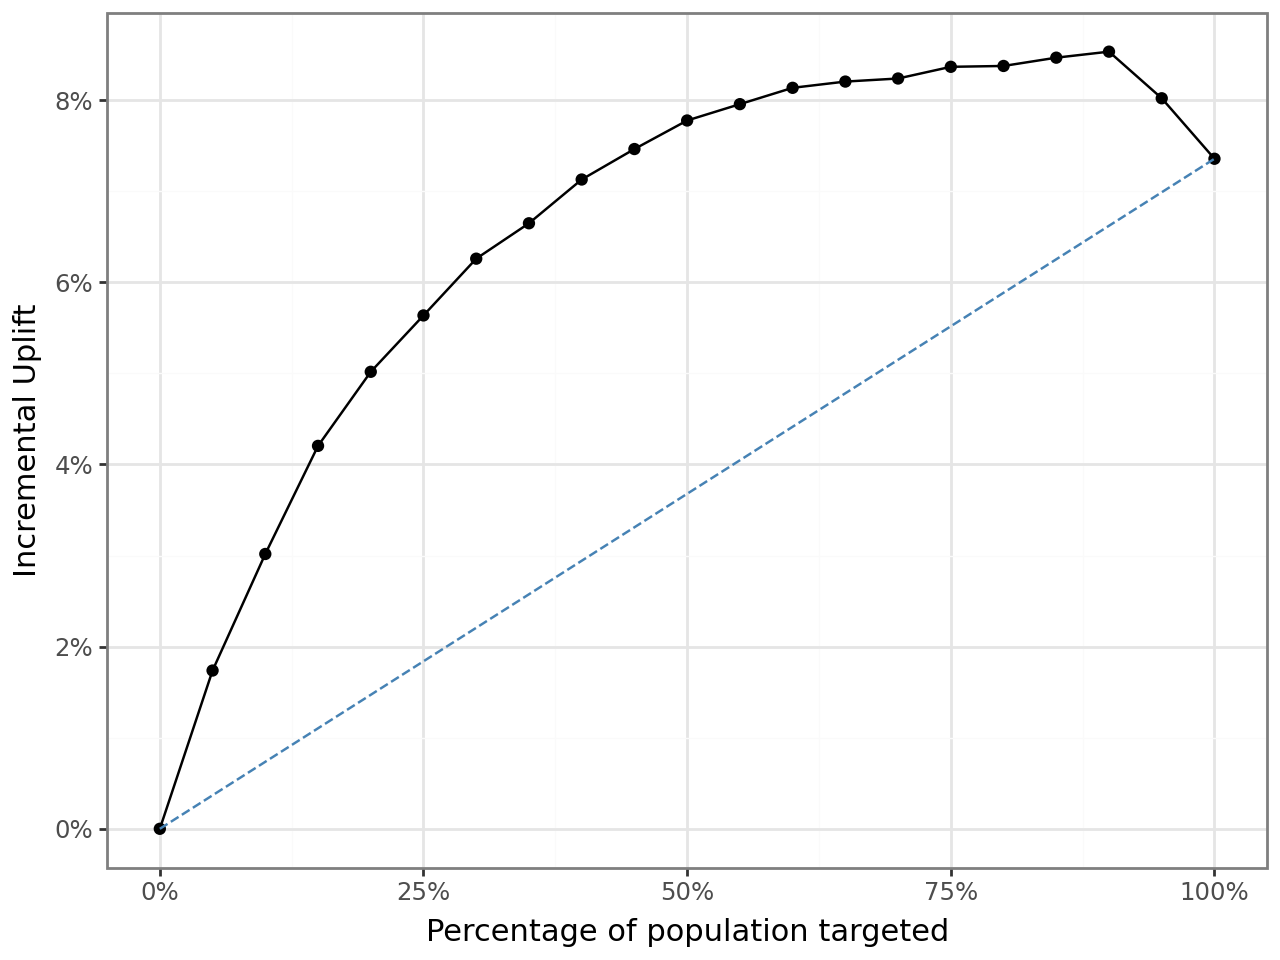

In [104]:
# Uplift PLOT FOR TUNED XGBOOST

Uplift_Curve_Xgboost = rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "uplift_xgb_tuned",
    "ad",
    1,
    qnt=20,
)

Uplift_Curve_Xgboost.show()

In [105]:
# Propensity TABLE for Tuned XGBOOST

tab_xgb_propensity = rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "pred_treat_xgb_tuned",  # XGB treatment probability
    "ad",
    1,
    qnt=20,
)

tab_xgb_propensity


pred,bins,cum_prop,T_resp,T_n,C_resp,C_n,incremental_resp,inc_uplift,uplift
str,i64,f64,u32,u32,u32,u32,f64,f64,f64
"""pred_treat_xgb_tuned""",1,0.05,212,450,77,574,151.634146,1.684824,0.336965
"""pred_treat_xgb_tuned""",2,0.1,355,900,130,1045,243.038278,2.700425,0.205251
"""pred_treat_xgb_tuned""",3,0.15,501,1350,181,1525,340.770492,3.786339,0.218194
"""pred_treat_xgb_tuned""",4,0.2,600,1800,228,2038,398.626104,4.429179,0.128382
"""pred_treat_xgb_tuned""",5,0.25,695,2250,278,2458,440.524817,4.89472,0.092063
…,…,…,…,…,…,…,…,…,…
"""pred_treat_xgb_tuned""",16,0.8,1136,7200,506,7246,633.212255,7.035692,0.026148
"""pred_treat_xgb_tuned""",17,0.85,1142,7650,507,7662,635.794049,7.064378,0.010929
"""pred_treat_xgb_tuned""",18,0.9,1157,8100,508,8100,649.0,7.211111,0.03105


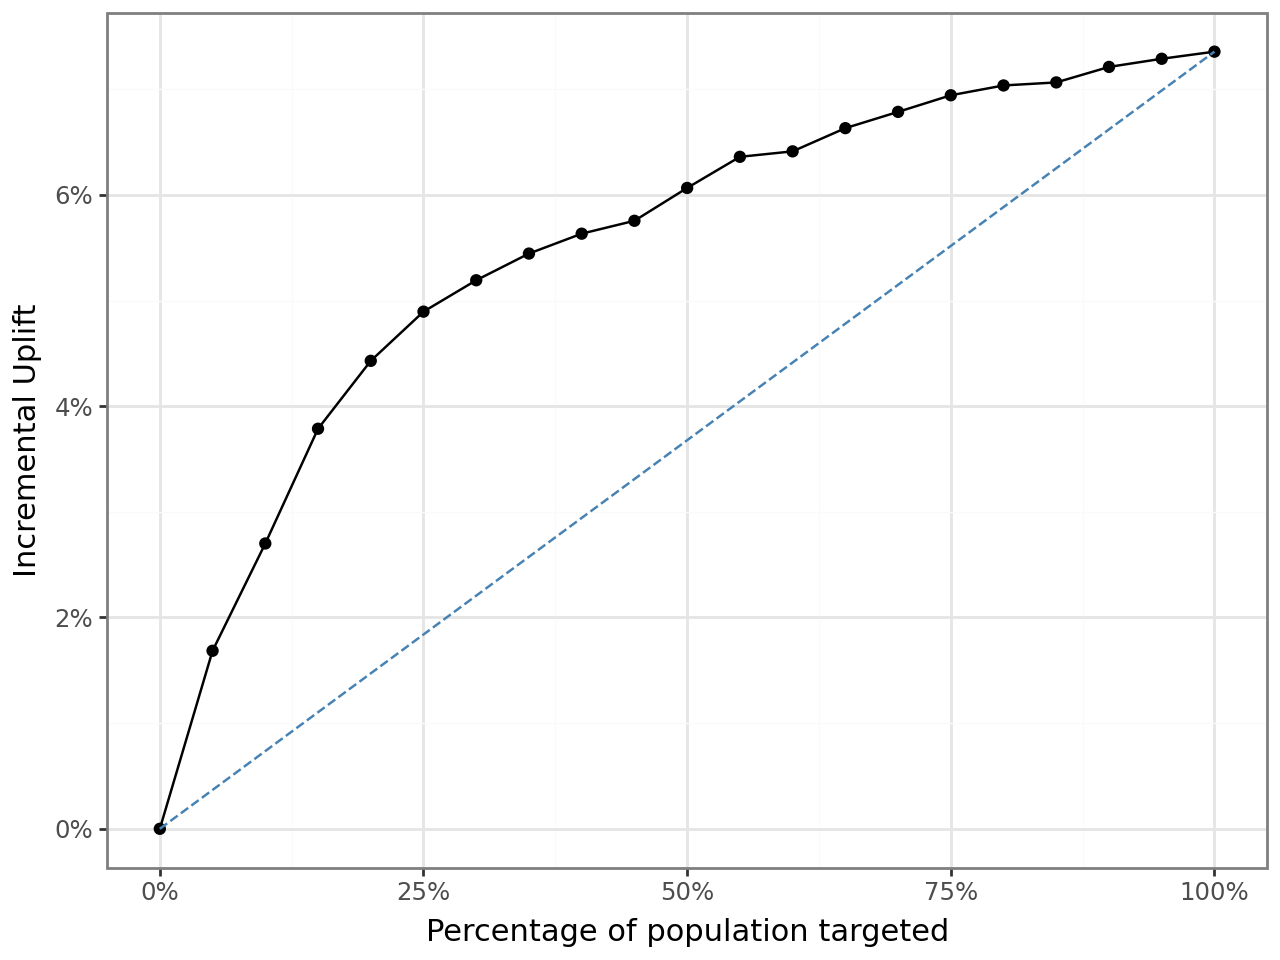

In [106]:
# Propensity Plot for Tuned XGBOOST

Propensity_Curve_Xgboost = rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "pred_treat_xgb_tuned",
    "ad",
    1,
    qnt=20,
)

Propensity_Curve_Xgboost.show()

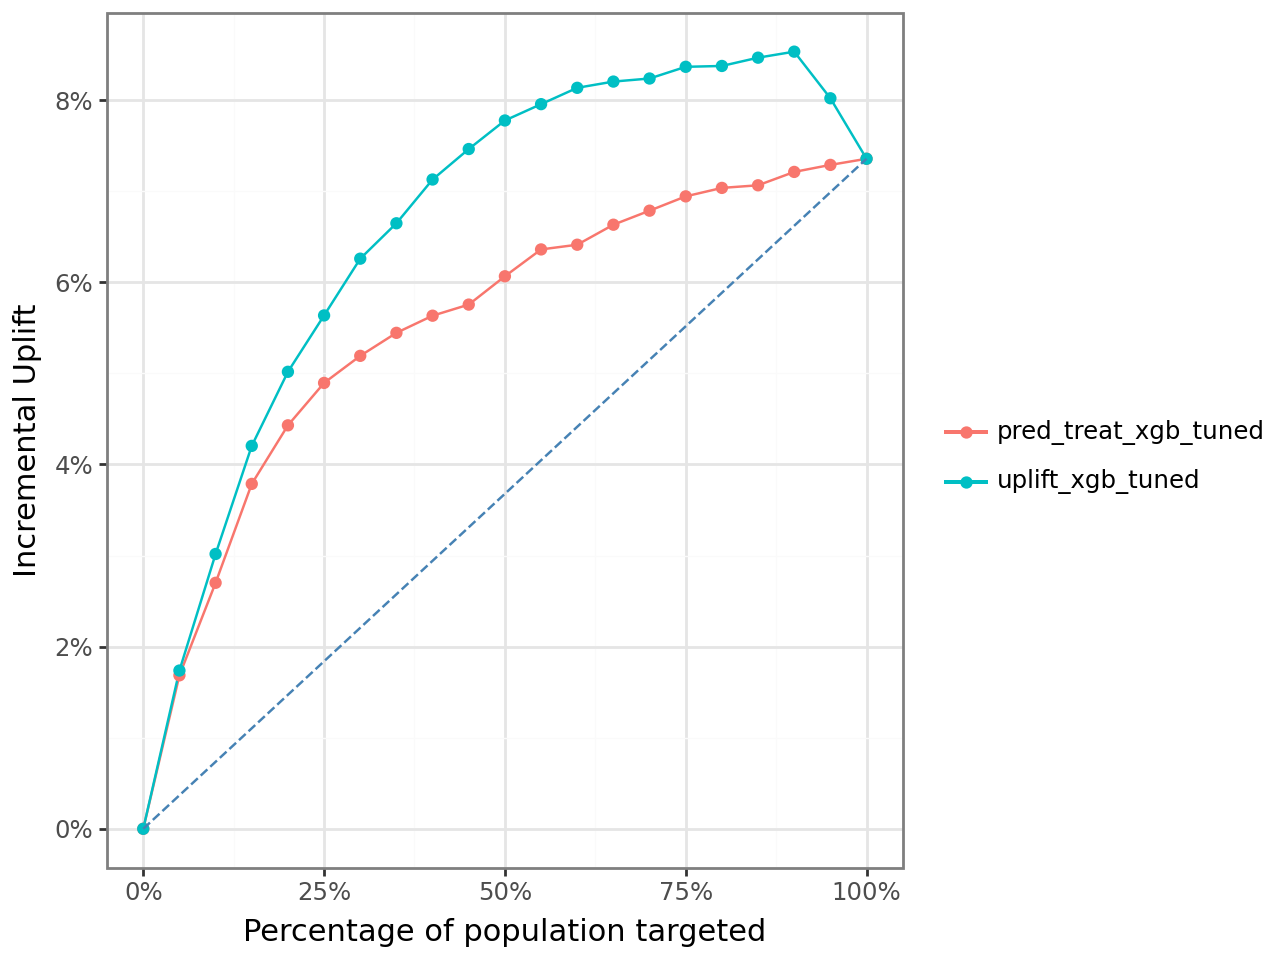

In [107]:
# Model Comparison Plot for Tuned XGBOOST

rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    [
        "pred_treat_xgb_tuned",  # XGB propensity
        "uplift_xgb_tuned",  # XGB uplift
    ],
    "ad",
    1,
    qnt=20,
)


In [108]:
# Incremental Profit (XGBoost Uplift Model)

target_customers = 30_000
treated_experiment = 9_000
revenue = 14.99
cost_per_customer = 1.50

# Build uplift table (test only)
tab_xgb_uplift = rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "uplift_xgb_tuned",
    "ad",
    1,
    qnt=20,
)

# 25% targeting → bin 5
bin5_xgb = tab_xgb_uplift.filter(pl.col("bins") == 5)

# Extract correct values
inc_resp_xgb = bin5_xgb.select("incremental_resp").item()
T_n_xgb = bin5_xgb.select("T_n").item()  # treated count up to bin 5

# Step 1: Compute incremental rate
inc_rate_xgb = inc_resp_xgb / T_n_xgb

# Step 2: Scale correctly to deployment size
incremental_responders_xgb = inc_rate_xgb * target_customers

# Profit
incremental_revenue_xgb = incremental_responders_xgb * revenue
total_cost_xgb = target_customers * cost_per_customer
incremental_profit_xgb = incremental_revenue_xgb - total_cost_xgb

print("=== XGBOOST UPLIFT MODEL ===")
print("Customers Targeted:", target_customers)
print("Incremental Responders:", round(incremental_responders_xgb, 2))
print("Incremental Profit:", round(incremental_profit_xgb, 2))


=== XGBOOST UPLIFT MODEL ===
Customers Targeted: 30000
Incremental Responders: 6762.7
Incremental Profit: 56372.82


In [109]:
# Incremental Profit (XGBoost Propensity Model)

target_customers = 30_000
treated_experiment = 9_000
revenue = 14.99
cost_per_customer = 1.50

# Build propensity table (test only)
tab_xgb_prop = rsm.model.uplift_tab(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    "pred_treat_xgb_tuned",
    "ad",
    1,
    qnt=20,
)

# 25% targeting → bin 5
bin5_xgb_prop = tab_xgb_prop.filter(pl.col("bins") == 5)

# Extract correct values
inc_resp_xgb_prop = bin5_xgb_prop.select("incremental_resp").item()
T_n_xgb_prop = bin5_xgb_prop.select("T_n").item()  # treated count up to bin 5

# Step 1: Compute incremental rate
inc_rate_xgb_prop = inc_resp_xgb_prop / T_n_xgb_prop

# Step 2: Scale correctly to deployment
incremental_responders_xgb_prop = inc_rate_xgb_prop * target_customers

# Profit
incremental_revenue_xgb_prop = incremental_responders_xgb_prop * revenue
total_cost_xgb_prop = target_customers * cost_per_customer
incremental_profit_xgb_prop = incremental_revenue_xgb_prop - total_cost_xgb_prop

print("=== XGBOOST PROPENSITY MODEL ===")
print("Customers Targeted:", target_customers)
print("Incremental Responders:", round(incremental_responders_xgb_prop, 2))
print("Incremental Profit:", round(incremental_profit_xgb_prop, 2))


=== XGBOOST PROPENSITY MODEL ===
Customers Targeted: 30000
Incremental Responders: 5873.66
Incremental Profit: 43046.23


### Comparison of All Models

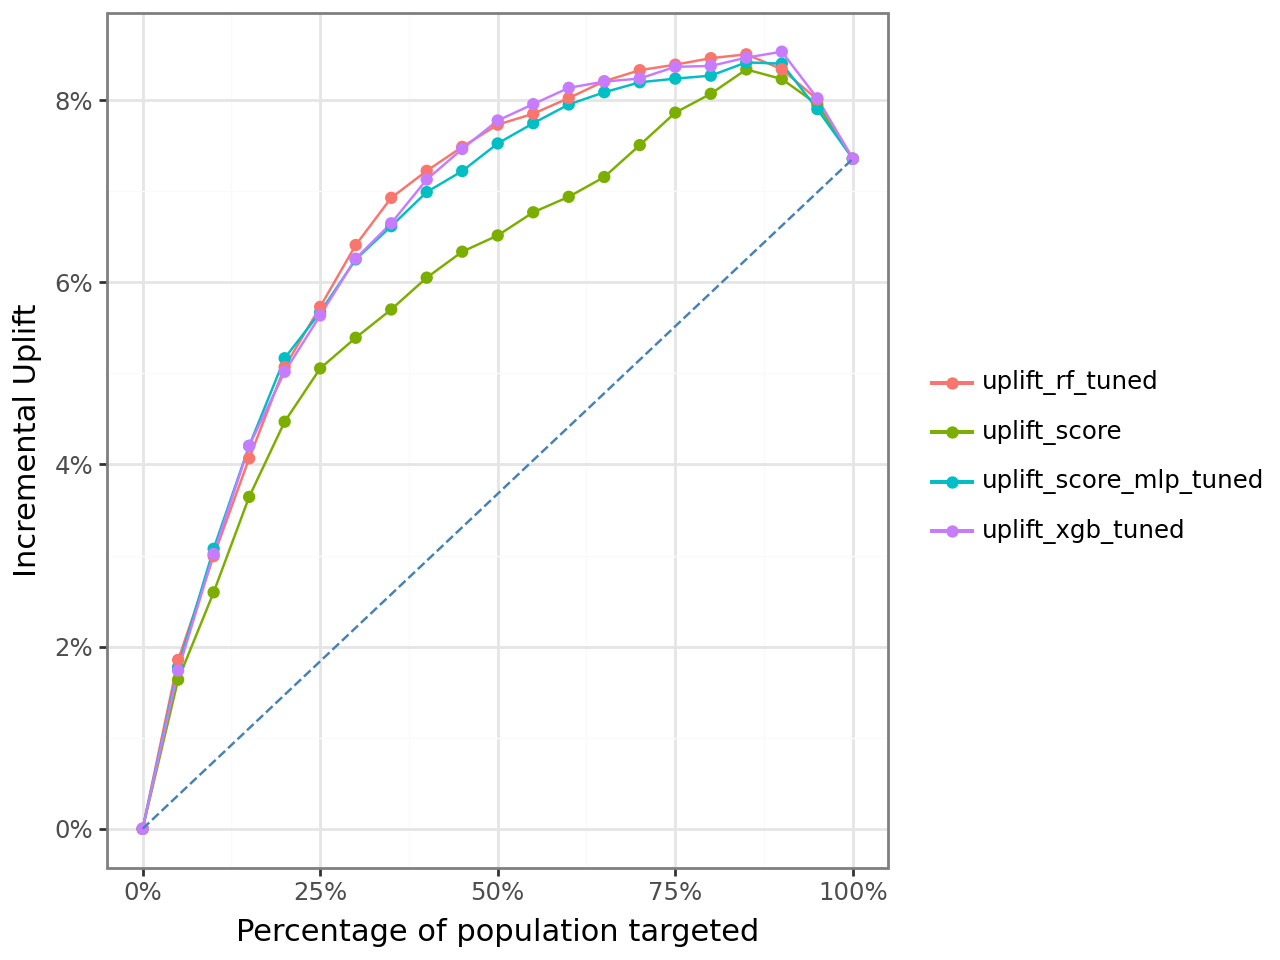

In [110]:
rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    [
        "uplift_score",  # Logistic
        "uplift_score_mlp_tuned",  # MLP
        "uplift_rf_tuned",  # RF
        "uplift_xgb_tuned",  # XGB
    ],
    "ad",
    1,
    qnt=20,
)


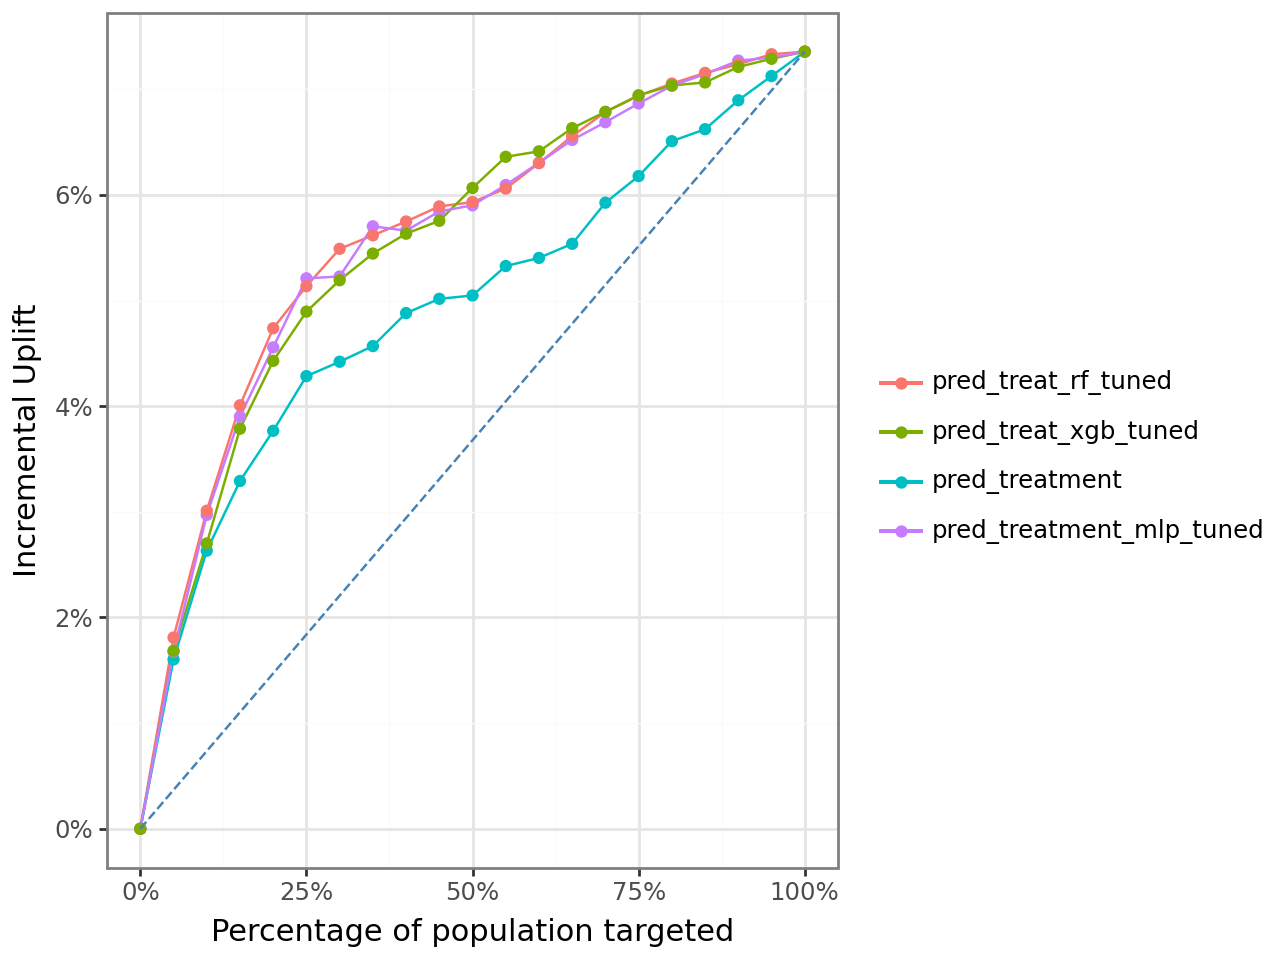

In [111]:
rsm.model.inc_uplift_plot(
    cg_rct_stacked.filter(pl.col("training") == 0),
    "converted",
    "yes",
    [
        "pred_treatment",  # Logistic
        "pred_treatment_mlp_tuned",  # MLP
        "pred_treat_rf_tuned",  # RF
        "pred_treat_xgb_tuned",  # XGB
    ],
    "ad",
    1,
    qnt=20,
)


In [112]:
profit_comparison = pl.DataFrame(
    {
        "Model": ["Logistic", "MLP", "RandomForest", "XGBoost"],
        "Uplift_Profit_25%": [
            incremental_profit_uplift_log,
            incremental_profit_mlp,
            incremental_profit_rf,
            incremental_profit_xgb,
        ],
        "Propensity_Profit_25%": [
            incremental_profit_prop_log,
            incremental_profit_prop_mlp,
            incremental_profit_rf_prop,
            incremental_profit_xgb_prop,
        ],
    }
).with_columns(
    (pl.col("Uplift_Profit_25%") - pl.col("Propensity_Profit_25%")).alias(
        "Uplift_Advantage"
    )
)

profit_comparison.sort("Uplift_Profit_25%", descending=True)


Model,Uplift_Profit_25%,Propensity_Profit_25%,Uplift_Advantage
str,f64,f64,f64
"""RandomForest""",58066.257733,47382.413959,10683.843774
"""MLP""",56996.777146,48719.326418,8277.450728
"""XGBoost""",56372.822472,43046.226743,13326.595729
"""Logistic""",45907.759762,45907.759762,0.0


# Part II: Targeting the optimal proportion of customers

# Logistic

In [113]:
# Optimal % Using Propensity Model For Logistic Regression

revenue = 14.99
cost_per_customer = 1.50

threshold = cost_per_customer / revenue

test_df = cg_rct_stacked.filter(pl.col("training") == 0)

# % to target under propensity
prop_target_pct = (
    test_df.filter(pl.col("pred_treatment") > threshold).height
) / test_df.height

print("Propensity Optimal %:", round(prop_target_pct * 100, 2))


Propensity Optimal %: 48.04


In [114]:
# Optimal % Using Uplift Model For Logistic Regression

uplift_target_pct = (
    test_df.filter(pl.col("uplift_score") > threshold).height
) / test_df.height

print("Uplift Optimal %:", round(uplift_target_pct * 100, 2))


Uplift Optimal %: 24.23


In [115]:
# Round to Nearest 5% and Extrapolate Profit For Logistic Regression
def round_to_5pct(x):
    return round(x * 20) / 20


prop_pct_rounded = round_to_5pct(prop_target_pct)
uplift_pct_rounded = round_to_5pct(uplift_target_pct)

print("Rounded Propensity %:", prop_pct_rounded * 100)
print("Rounded Uplift %:", uplift_pct_rounded * 100)


Rounded Propensity %: 50.0
Rounded Uplift %: 25.0


In [116]:
# Convert % to Bin Number
prop_bin = int(prop_pct_rounded * 20)
uplift_bin = int(uplift_pct_rounded * 20)


In [117]:
# Profit at Optimal % -- Propensity For Logistic Regression

total_customers = 120_000  # full population size

bin_prop = tab_prop.filter(pl.col("bins") == prop_bin)

inc_resp_prop = bin_prop.select("incremental_resp").item()
T_n_prop = bin_prop.select("T_n").item()

inc_rate_prop = inc_resp_prop / T_n_prop

incremental_responders_prop = inc_rate_prop * 30_000

profit_prop = incremental_responders_prop * revenue - 30_000 * cost_per_customer

# 🔹 Number of customers targeted
customers_targeted_prop = int(prop_pct_rounded * total_customers)

print("Propensity Target %:", round(prop_pct_rounded * 100, 2))
print("Customers Targeted:", customers_targeted_prop)
print("Propensity Profit (Optimal %):", round(profit_prop, 2))


Propensity Target %: 50.0
Customers Targeted: 60000
Propensity Profit (Optimal %): 399.93


In [118]:
# Profit at Optimal % — Uplift For Logistic Regression

total_customers = 120_000  # full population size

bin_uplift = tab.filter(pl.col("bins") == uplift_bin)

inc_resp_uplift = bin_uplift.select("incremental_resp").item()
T_n_uplift = bin_uplift.select("T_n").item()

inc_rate_uplift = inc_resp_uplift / T_n_uplift
incremental_responders_uplift = inc_rate_uplift * 30_000

profit_uplift = incremental_responders_uplift * revenue - 30_000 * cost_per_customer

# 🔹 Number of customers targeted
customers_targeted_uplift = int(uplift_pct_rounded * total_customers)

print("Uplift Target %:", round(uplift_pct_rounded * 100, 2))
print("Customers Targeted:", customers_targeted_uplift)
print("Uplift Profit (Optimal %):", round(profit_uplift, 2))


Uplift Target %: 25.0
Customers Targeted: 30000
Uplift Profit (Optimal %): 45907.76


# MLP

In [119]:
# Optimal % Using Propensity Model For MLP

revenue = 14.99
cost_per_customer = 1.50
threshold = cost_per_customer / revenue

test_df = cg_rct_stacked.filter(pl.col("training") == 0)

prop_target_pct_mlp = (
    test_df.filter(pl.col("pred_treatment_mlp_tuned") > threshold).height
) / test_df.height

print("MLP Propensity Optimal %:", round(prop_target_pct_mlp * 100, 2))


MLP Propensity Optimal %: 45.29


In [120]:
# Optimal % Using Uplift Model For MLP

uplift_target_pct_mlp = (
    test_df.filter(pl.col("uplift_score_mlp_tuned") > threshold).height
) / test_df.height

print("MLP Uplift Optimal %:", round(uplift_target_pct_mlp * 100, 2))


MLP Uplift Optimal %: 33.25


In [121]:
# Round to Nearest 5% and Extrapolate Profit For MLP


def round_to_5pct(x):
    return round(x * 20) / 20


prop_pct_rounded_mlp = round_to_5pct(prop_target_pct_mlp)
uplift_pct_rounded_mlp = round_to_5pct(uplift_target_pct_mlp)

print("Rounded MLP Propensity %:", prop_pct_rounded_mlp * 100)
print("Rounded MLP Uplift %:", uplift_pct_rounded_mlp * 100)


Rounded MLP Propensity %: 45.0
Rounded MLP Uplift %: 35.0


In [122]:
prop_bin_mlp = int(prop_pct_rounded_mlp * 20)
uplift_bin_mlp = int(uplift_pct_rounded_mlp * 20)


In [123]:
# Profit at Optimal % -- Propensity For MLP

total_customers = 120_000

bin_prop_mlp = tab_prop_mlp.filter(pl.col("bins") == prop_bin_mlp)

inc_resp_prop_mlp = bin_prop_mlp.select("incremental_resp").item()
T_n_prop_mlp = bin_prop_mlp.select("T_n").item()

inc_rate_prop_mlp = inc_resp_prop_mlp / T_n_prop_mlp
incremental_responders_prop_mlp = inc_rate_prop_mlp * 30_000

profit_prop_mlp = incremental_responders_prop_mlp * revenue - 30_000 * cost_per_customer

customers_targeted_prop_mlp = int(prop_pct_rounded_mlp * total_customers)

print("MLP Propensity Target %:", prop_pct_rounded_mlp * 100)
print("Customers Targeted:", customers_targeted_prop_mlp)
print("MLP Propensity Profit (Optimal %):", round(profit_prop_mlp, 2))


MLP Propensity Target %: 45.0
Customers Targeted: 54000
MLP Propensity Profit (Optimal %): 13392.74


In [124]:
# Profit at Optimal % — Uplift For MLP

bin_uplift_mlp = tab_mlp.filter(pl.col("bins") == uplift_bin_mlp)

inc_resp_uplift_mlp = bin_uplift_mlp.select("incremental_resp").item()
T_n_uplift_mlp = bin_uplift_mlp.select("T_n").item()

inc_rate_uplift_mlp = inc_resp_uplift_mlp / T_n_uplift_mlp
incremental_responders_uplift_mlp = inc_rate_uplift_mlp * 30_000

profit_uplift_mlp = (
    incremental_responders_uplift_mlp * revenue - 30_000 * cost_per_customer
)

customers_targeted_uplift_mlp = int(uplift_pct_rounded_mlp * total_customers)

print("MLP Uplift Target %:", uplift_pct_rounded_mlp * 100)
print("Customers Targeted:", customers_targeted_uplift_mlp)
print("MLP Uplift Profit (Optimal %):", round(profit_uplift_mlp, 2))


MLP Uplift Target %: 35.0
Customers Targeted: 42000
MLP Uplift Profit (Optimal %): 39996.02


# RF

In [125]:
# Optimal % Using RF Propensity Model

revenue = 14.99
cost_per_customer = 1.50
threshold = cost_per_customer / revenue

test_df = cg_rct_stacked.filter(pl.col("training") == 0)

rf_prop_target_pct = (
    test_df.filter(pl.col("pred_treat_rf_tuned") > threshold).height
) / test_df.height

print("RF Propensity Optimal %:", round(rf_prop_target_pct * 100, 2))


RF Propensity Optimal %: 51.42


In [126]:
# Optimal % Using RF Uplift Model

rf_uplift_target_pct = (
    test_df.filter(pl.col("uplift_rf_tuned") > threshold).height
) / test_df.height

print("RF Uplift Optimal %:", round(rf_uplift_target_pct * 100, 2))


RF Uplift Optimal %: 31.71


In [127]:
# Round to Nearest 5% and Extrapolate Profit For RF


def round_to_5pct(x):
    return round(x * 20) / 20


rf_prop_pct_rounded = round_to_5pct(rf_prop_target_pct)
rf_uplift_pct_rounded = round_to_5pct(rf_uplift_target_pct)

print("Rounded RF Propensity %:", rf_prop_pct_rounded * 100)
print("Rounded RF Uplift %:", rf_uplift_pct_rounded * 100)


Rounded RF Propensity %: 50.0
Rounded RF Uplift %: 30.0


In [128]:
rf_prop_bin = int(rf_prop_pct_rounded * 20)
rf_uplift_bin = int(rf_uplift_pct_rounded * 20)


In [129]:
# Profit at Optimal % -- Propensity For RF

total_customers = 120_000

bin_rf_prop = tab_rf_prop.filter(pl.col("bins") == rf_prop_bin)

inc_resp_rf_prop = bin_rf_prop.select("incremental_resp").item()
T_n_rf_prop = bin_rf_prop.select("T_n").item()

inc_rate_rf_prop = inc_resp_rf_prop / T_n_rf_prop
incremental_responders_rf_prop = inc_rate_rf_prop * 30_000

profit_rf_prop = incremental_responders_rf_prop * revenue - 30_000 * cost_per_customer

customers_targeted_rf_prop = int(rf_prop_pct_rounded * total_customers)

print("RF Propensity Target %:", rf_prop_pct_rounded * 100)
print("Customers Targeted:", customers_targeted_rf_prop)
print("RF Propensity Profit (Optimal %):", round(profit_rf_prop, 2))


RF Propensity Target %: 50.0
Customers Targeted: 60000
RF Propensity Profit (Optimal %): 8349.33


In [130]:
# Profit at Optimal % — Uplift For RF

bin_rf_uplift = tab_rf_uplift.filter(pl.col("bins") == rf_uplift_bin)

inc_resp_rf_uplift = bin_rf_uplift.select("incremental_resp").item()
T_n_rf_uplift = bin_rf_uplift.select("T_n").item()

inc_rate_rf_uplift = inc_resp_rf_uplift / T_n_rf_uplift
incremental_responders_rf_uplift = inc_rate_rf_uplift * 30_000

profit_rf_uplift = (
    incremental_responders_rf_uplift * revenue - 30_000 * cost_per_customer
)

customers_targeted_rf_uplift = int(rf_uplift_pct_rounded * total_customers)

print("RF Uplift Target %:", rf_uplift_pct_rounded * 100)
print("Customers Targeted:", customers_targeted_rf_uplift)
print("RF Uplift Profit (Optimal %):", round(profit_rf_uplift, 2))


RF Uplift Target %: 30.0
Customers Targeted: 36000
RF Uplift Profit (Optimal %): 51059.89


# Xgboost


In [131]:
# Optimal % Using XGBoost Propensity Model

revenue = 14.99
cost_per_customer = 1.50
threshold = cost_per_customer / revenue

test_df = cg_rct_stacked.filter(pl.col("training") == 0)

xgb_prop_target_pct = (
    test_df.filter(pl.col("pred_treat_xgb_tuned") > threshold).height
) / test_df.height

print("XGB Propensity Optimal %:", round(xgb_prop_target_pct * 100, 2))


XGB Propensity Optimal %: 49.14


In [132]:
# Optimal % Using XGBoost Uplift Model

xgb_uplift_target_pct = (
    test_df.filter(pl.col("uplift_xgb_tuned") > threshold).height
) / test_df.height

print("XGB Uplift Optimal %:", round(xgb_uplift_target_pct * 100, 2))


XGB Uplift Optimal %: 31.14


In [133]:
# Round to Nearest 5% and Extrapolate Profit For Xgboost


def round_to_5pct(x):
    return round(x * 20) / 20


xgb_prop_pct_rounded = round_to_5pct(xgb_prop_target_pct)
xgb_uplift_pct_rounded = round_to_5pct(xgb_uplift_target_pct)

print("Rounded XGB Propensity %:", xgb_prop_pct_rounded * 100)
print("Rounded XGB Uplift %:", xgb_uplift_pct_rounded * 100)


Rounded XGB Propensity %: 50.0
Rounded XGB Uplift %: 30.0


In [134]:
xgb_prop_bin = int(xgb_prop_pct_rounded * 20)
xgb_uplift_bin = int(xgb_uplift_pct_rounded * 20)


In [135]:
# Profit at Optimal % — Propensity For Xgboost

total_customers = 120_000

bin_xgb_prop = tab_xgb_prop.filter(pl.col("bins") == xgb_prop_bin)

inc_resp_xgb_prop = bin_xgb_prop.select("incremental_resp").item()
T_n_xgb_prop = bin_xgb_prop.select("T_n").item()

inc_rate_xgb_prop = inc_resp_xgb_prop / T_n_xgb_prop
incremental_responders_xgb_prop = inc_rate_xgb_prop * 30_000

profit_xgb_prop = incremental_responders_xgb_prop * revenue - 30_000 * cost_per_customer

customers_targeted_xgb_prop = int(xgb_prop_pct_rounded * total_customers)

print("XGB Propensity Target %:", xgb_prop_pct_rounded * 100)
print("Customers Targeted:", customers_targeted_xgb_prop)
print("XGB Propensity Profit (Optimal %):", round(profit_xgb_prop, 2))


XGB Propensity Target %: 50.0
Customers Targeted: 60000
XGB Propensity Profit (Optimal %): 9553.98


In [136]:
# Profit at Optimal % — Uplift For Xgboost

bin_xgb_uplift = tab_xgb_uplift.filter(pl.col("bins") == xgb_uplift_bin)

inc_resp_xgb_uplift = bin_xgb_uplift.select("incremental_resp").item()
T_n_xgb_uplift = bin_xgb_uplift.select("T_n").item()

inc_rate_xgb_uplift = inc_resp_xgb_uplift / T_n_xgb_uplift
incremental_responders_xgb_uplift = inc_rate_xgb_uplift * 30_000

profit_xgb_uplift = (
    incremental_responders_xgb_uplift * revenue - 30_000 * cost_per_customer
)

customers_targeted_xgb_uplift = int(xgb_uplift_pct_rounded * total_customers)

print("XGB Uplift Target %:", xgb_uplift_pct_rounded * 100)
print("Customers Targeted:", customers_targeted_xgb_uplift)
print("XGB Uplift Profit (Optimal %):", round(profit_xgb_uplift, 2))


XGB Uplift Target %: 30.0
Customers Targeted: 36000
XGB Uplift Profit (Optimal %): 48818.94


# Model Comparison at Optimal Targeting %

In [137]:
optimal_comparison = pl.DataFrame(
    {
        "Model": ["Logistic", "MLP", "RandomForest", "XGBoost"],
        "Uplift_Optimal_%": [
            uplift_pct_rounded * 100,
            uplift_pct_rounded_mlp * 100,
            rf_uplift_pct_rounded * 100,
            xgb_uplift_pct_rounded * 100,
        ],
        "Propensity_Optimal_%": [
            prop_pct_rounded * 100,
            prop_pct_rounded_mlp * 100,
            rf_prop_pct_rounded * 100,
            xgb_prop_pct_rounded * 100,
        ],
        "Uplift_Profit_Optimal": [
            profit_uplift,
            profit_uplift_mlp,
            profit_rf_uplift,
            profit_xgb_uplift,
        ],
        "Propensity_Profit_Optimal": [
            profit_prop,
            profit_prop_mlp,
            profit_rf_prop,
            profit_xgb_prop,
        ],
    }
).with_columns(
    (pl.col("Uplift_Profit_Optimal") - pl.col("Propensity_Profit_Optimal")).alias(
        "Uplift_Advantage_Optimal"
    )
)

optimal_comparison.sort("Uplift_Profit_Optimal", descending=True)


Model,Uplift_Optimal_%,Propensity_Optimal_%,Uplift_Profit_Optimal,Propensity_Profit_Optimal,Uplift_Advantage_Optimal
str,f64,f64,f64,f64,f64
"""RandomForest""",30.0,50.0,51059.891078,8349.334009,42710.557069
"""XGBoost""",30.0,50.0,48818.937793,9553.979358,39264.958435
"""Logistic""",25.0,50.0,45907.759762,399.931875,45507.827886
"""MLP""",35.0,45.0,39996.0239,13392.740415,26603.283485


## II.7 Why does one approach outperform the other in incremental profit?

### 1. Uplift models target incremental responders (Persuadables), not just likely buyers

A **propensity-to-buy model** ranks customers by their likelihood of purchasing if treated.  
However, this often prioritizes:

- **Sure Things** (customers who would buy anyway)
- Customers with high baseline purchase probability

Targeting these customers generates little or **no incremental profit**, since they would have converted even without the campaign.

In contrast, an **uplift model** estimates the causal treatment effect:

Uplift = P(Buy | Treated) − P(Buy | Control)

This directly identifies **Persuadables** — customers who buy *because* of the treatment.

By focusing on customers whose behavior actually changes, uplift models avoid wasting budget on:

- Sure Things  
- Lost Causes (unlikely to buy regardless)

As a result, uplift modeling typically produces **higher incremental profit** at its optimal targeting percentage.

---

### 2. Uplift models avoid zero and negative treatment effects

Propensity models do not distinguish between:

- Customers positively influenced by treatment  
- Customers unaffected by treatment  
- Customers negatively influenced by treatment (“Sleeping Dogs” / Do Not Disturbs)

Because of this, propensity targeting may:

- Waste spend on customers with zero incremental effect  
- Reduce profit by targeting negatively affected customers  

Uplift models explicitly separate these groups and:

- Target only customers with **positive uplift**  
- Avoid customers with **negative uplift**  
- Stop targeting once marginal uplift becomes unprofitable  

This results in:

- More selective targeting  
- Higher profit per targeted customer  
- Higher overall incremental profit  

---

### Conclusion

Propensity models maximize **purchase probability**, whereas uplift models maximize **incremental impact**.

Since incremental profit depends on targeting customers whose behavior changes due to treatment, **uplift modeling outperforms propensity-based targeting when evaluated on incremental profit.**
